In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2018.scaled')
data={
    '2018':{
        'sre': 'EGamma',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'EGamma',
        'ttbare': 'EGamma',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [ ]:
data_hists['mT_corrected'].integrate("systematic").integrate('region','wjete')[data['2018']['sre']].values()

In [ ]:
signal_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').values()

In [ ]:
data_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').values()[('EGamma',)]/bkg_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').sum('process').values()[()]

In [ ]:
signal_hists

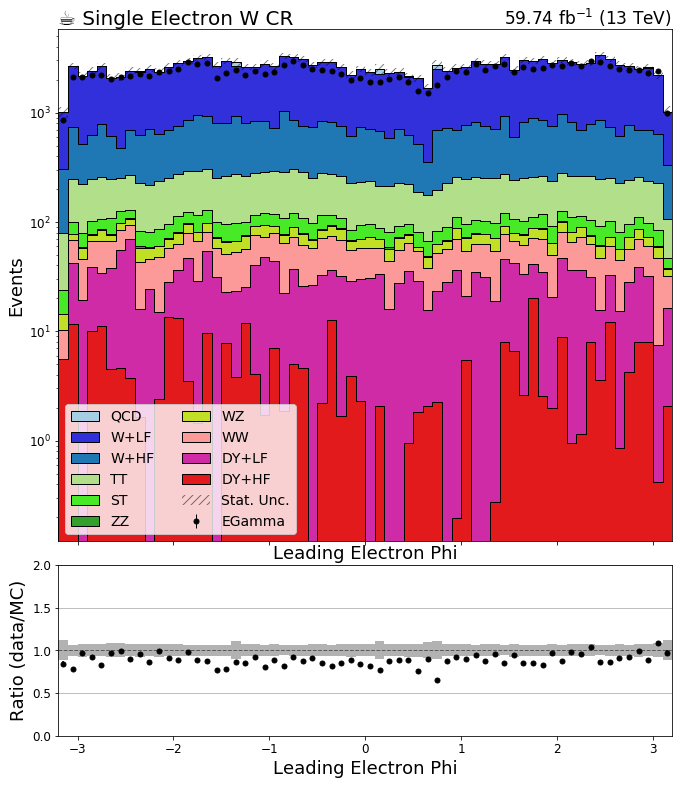

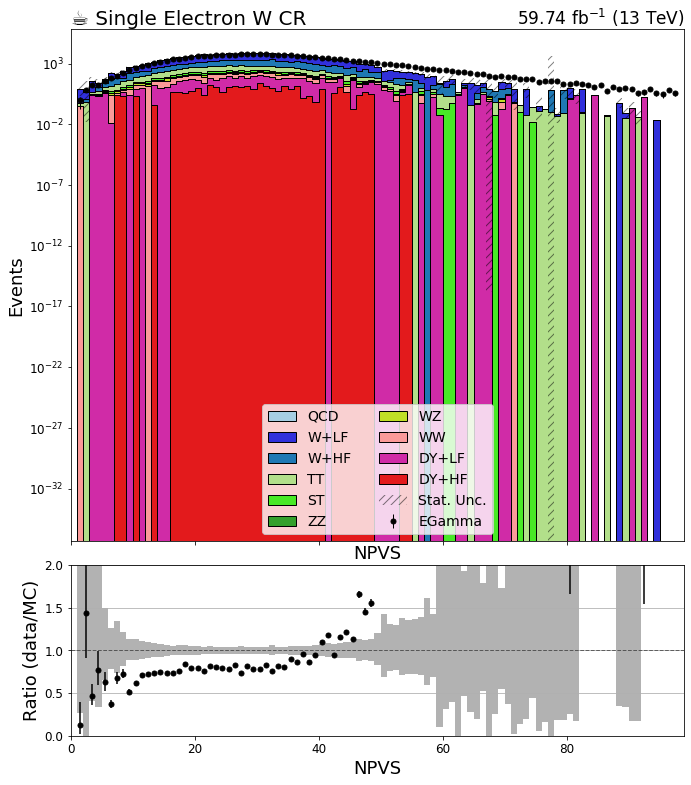

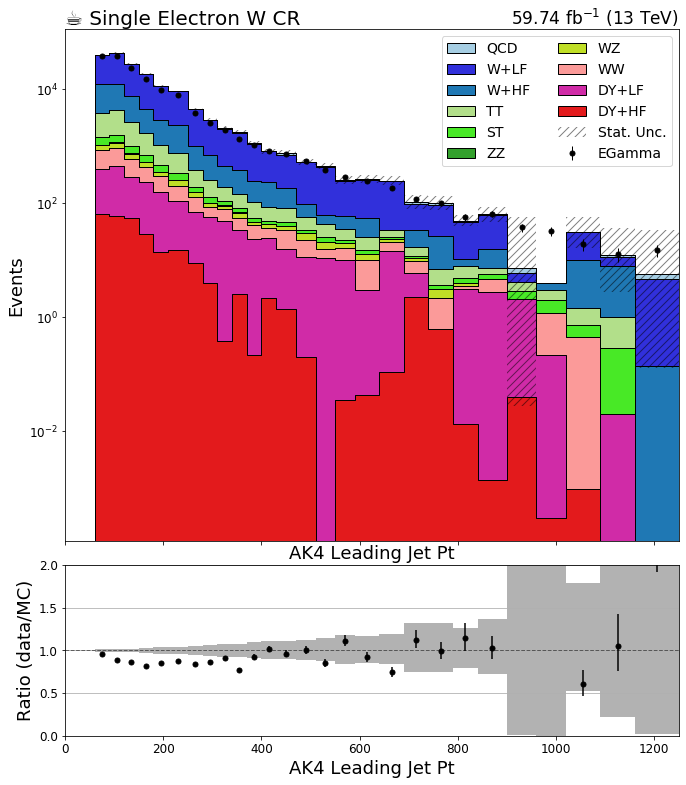

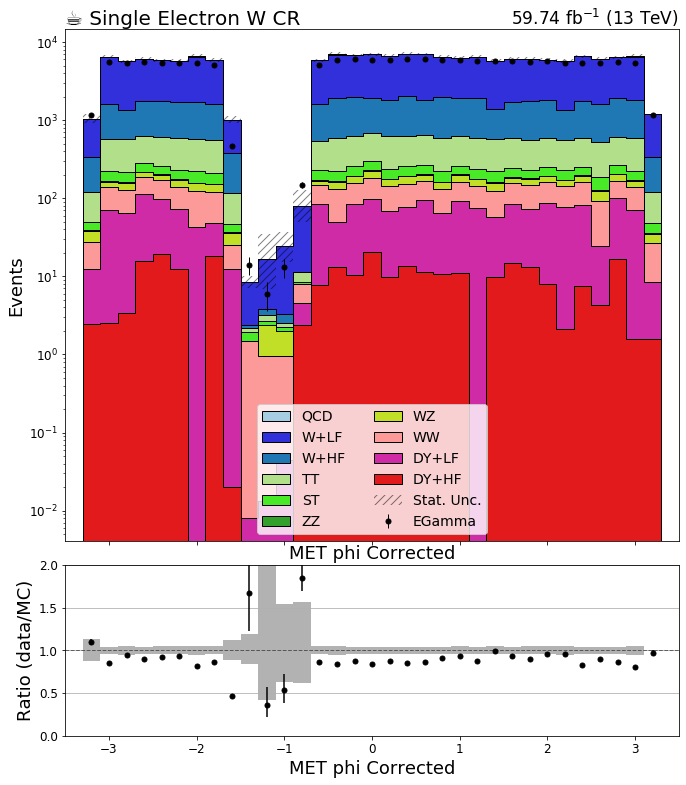

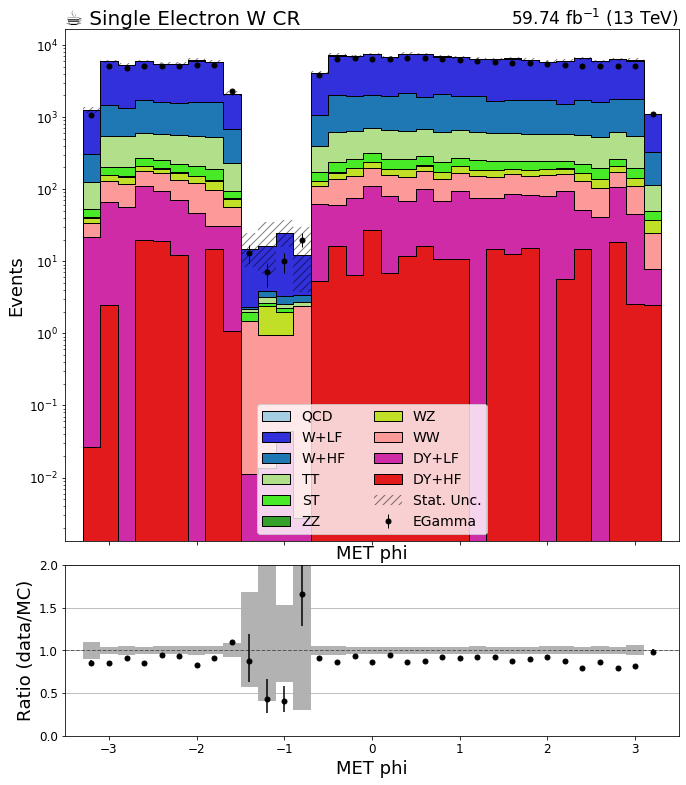

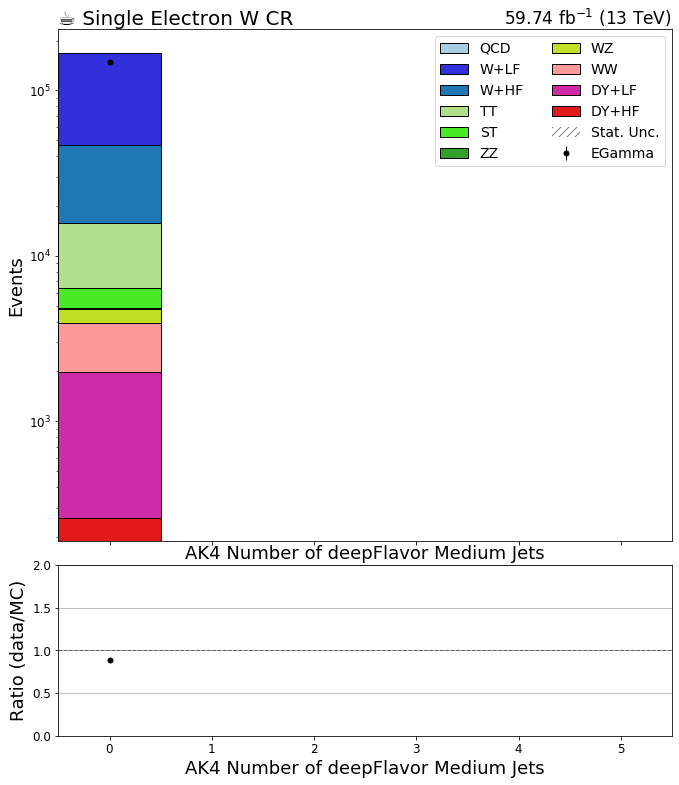

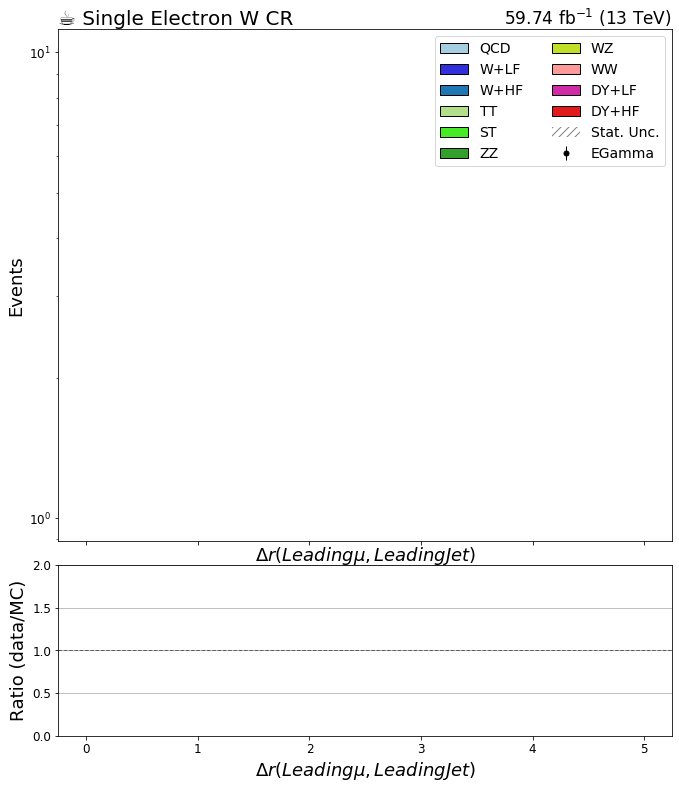

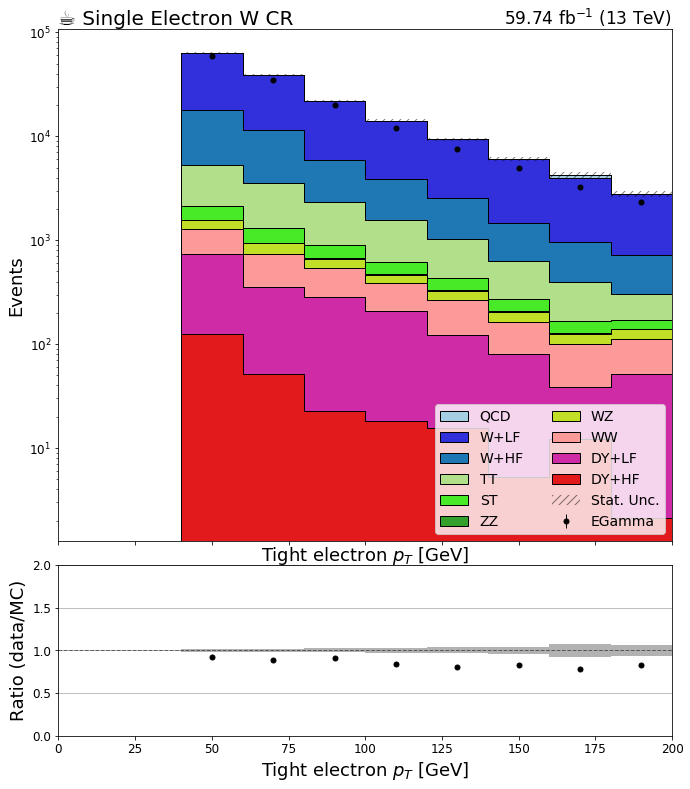

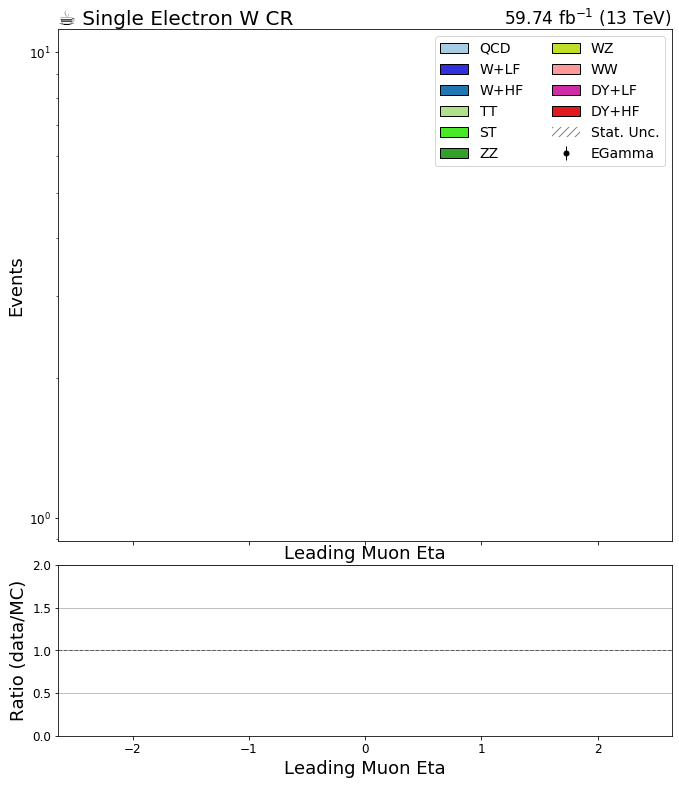

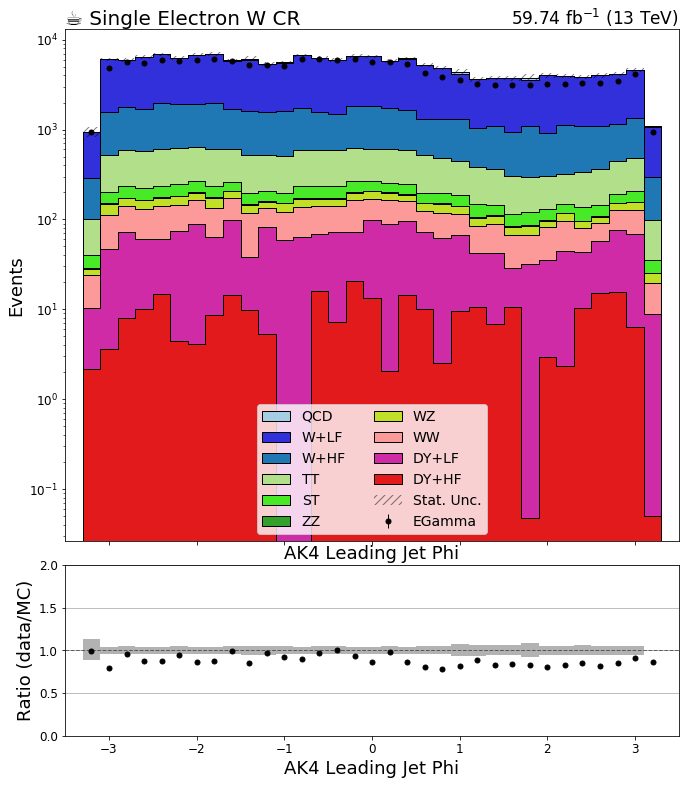

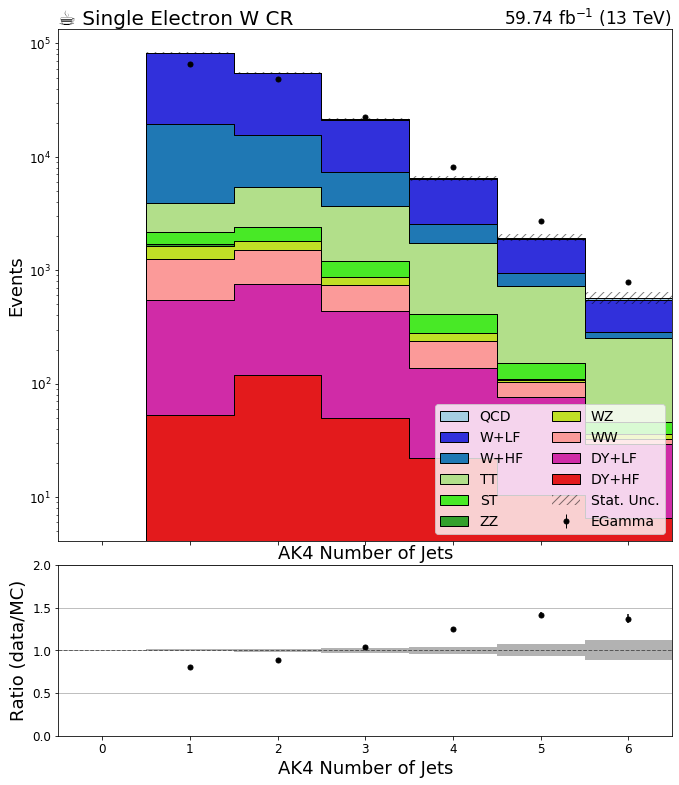

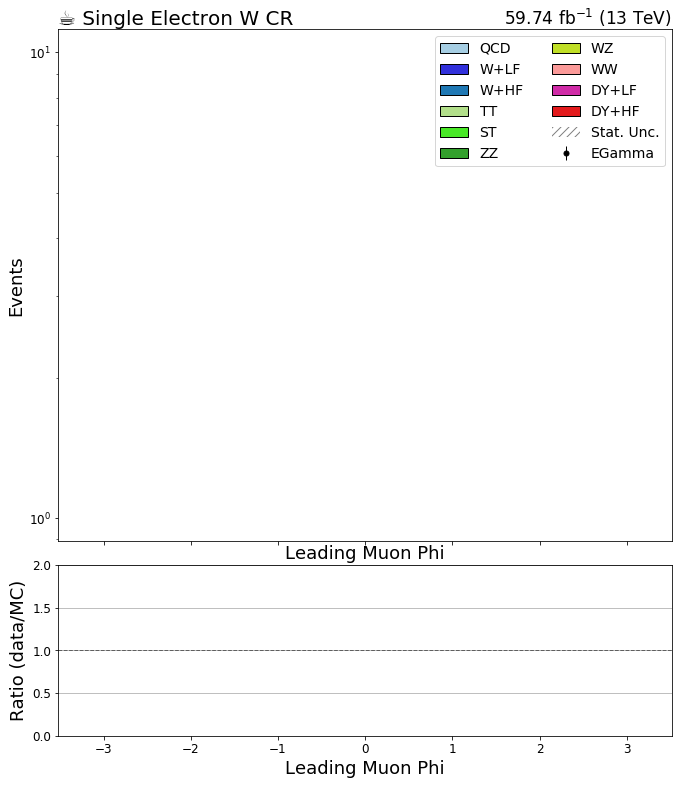

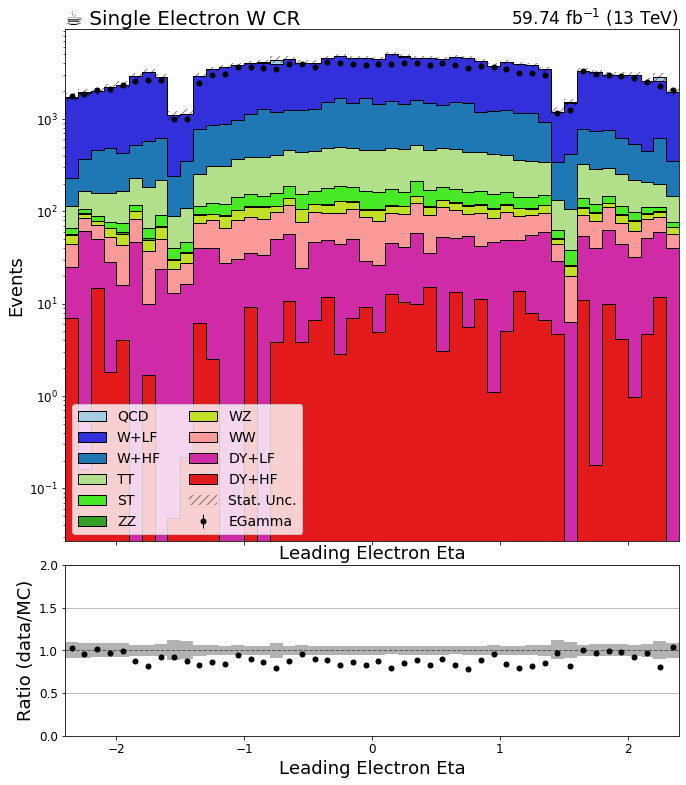

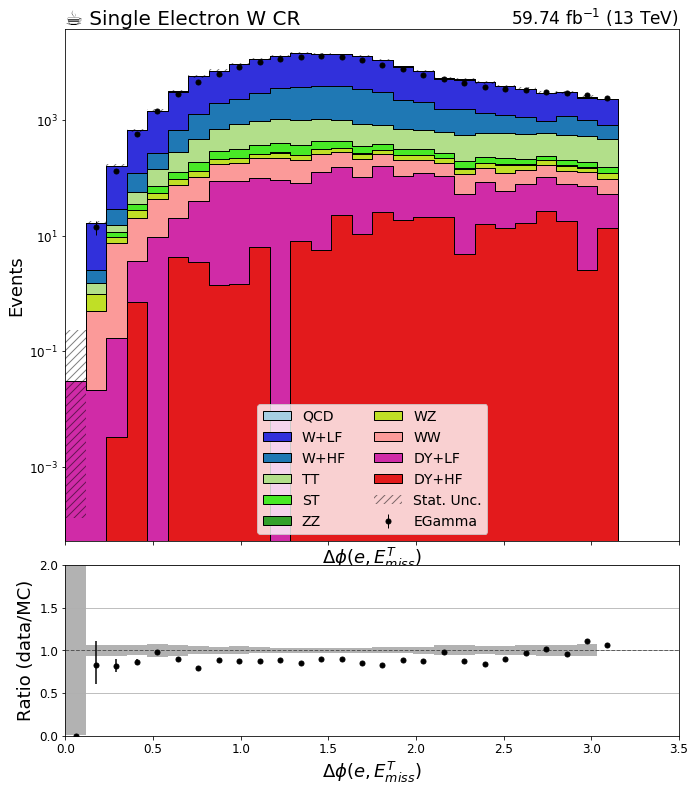

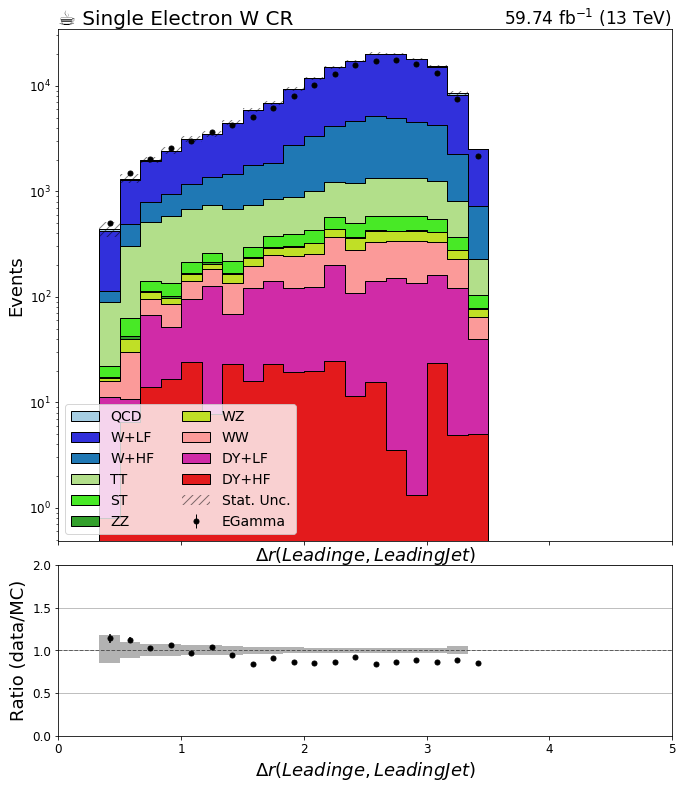

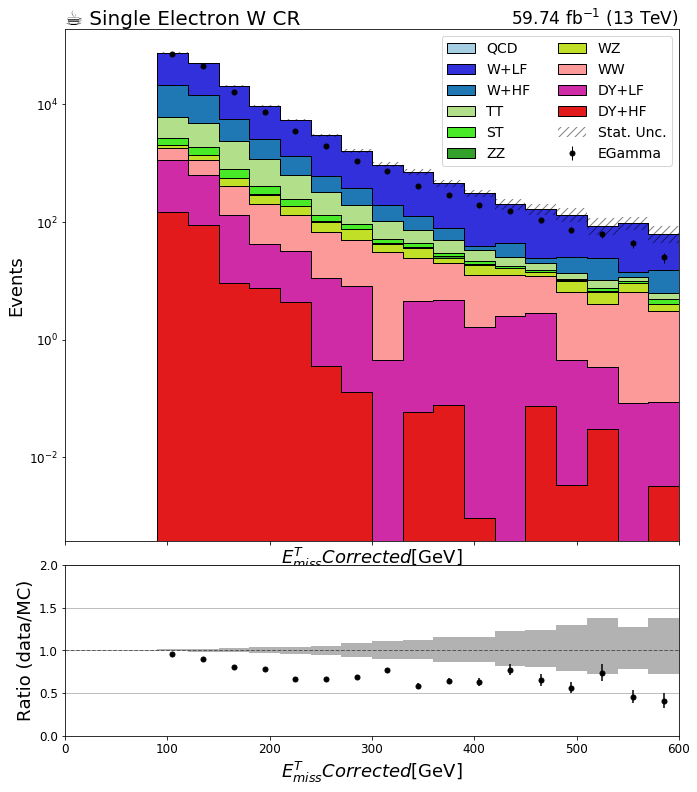

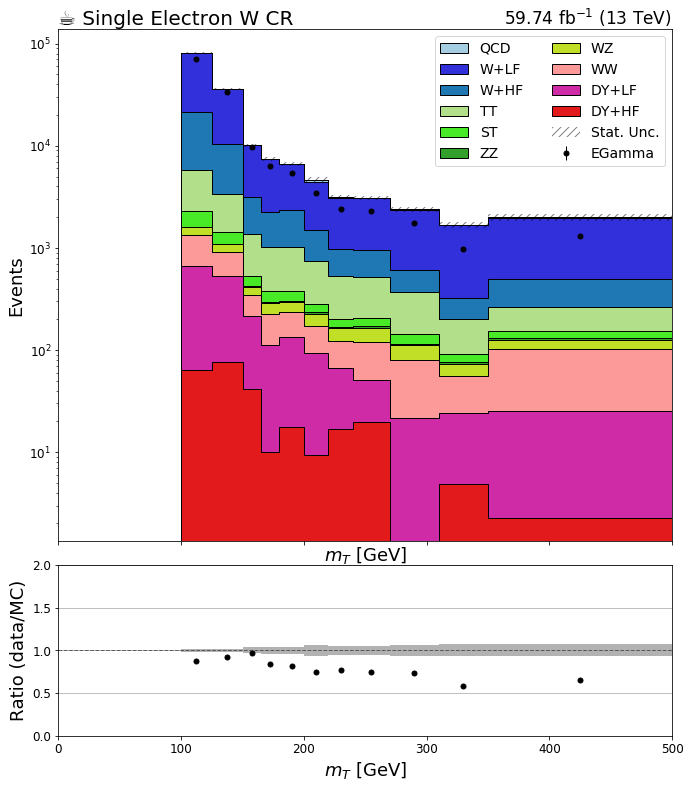

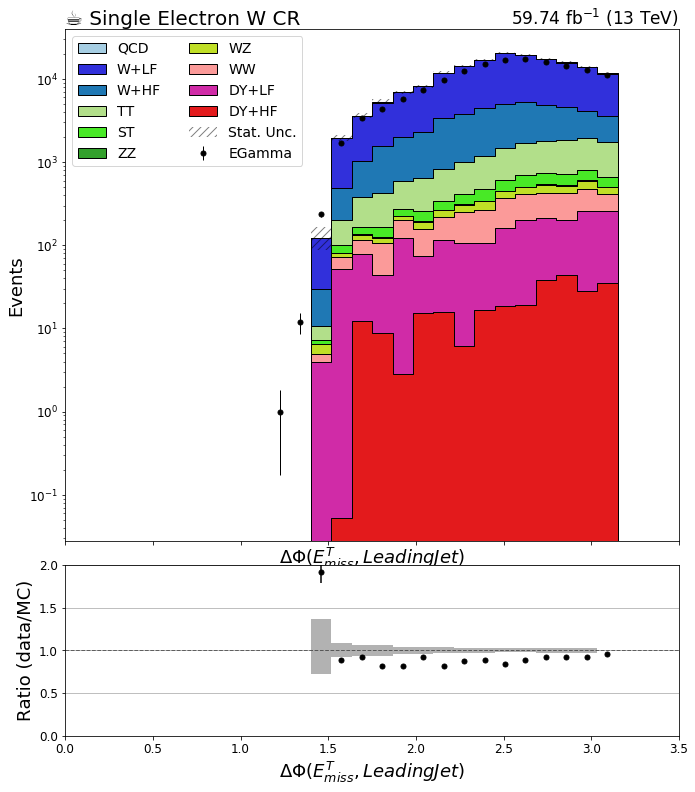

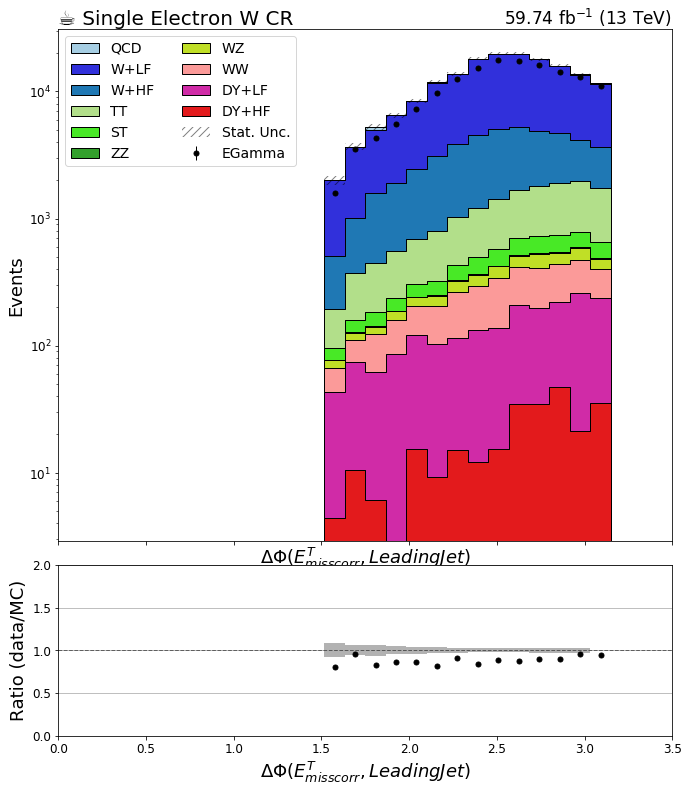

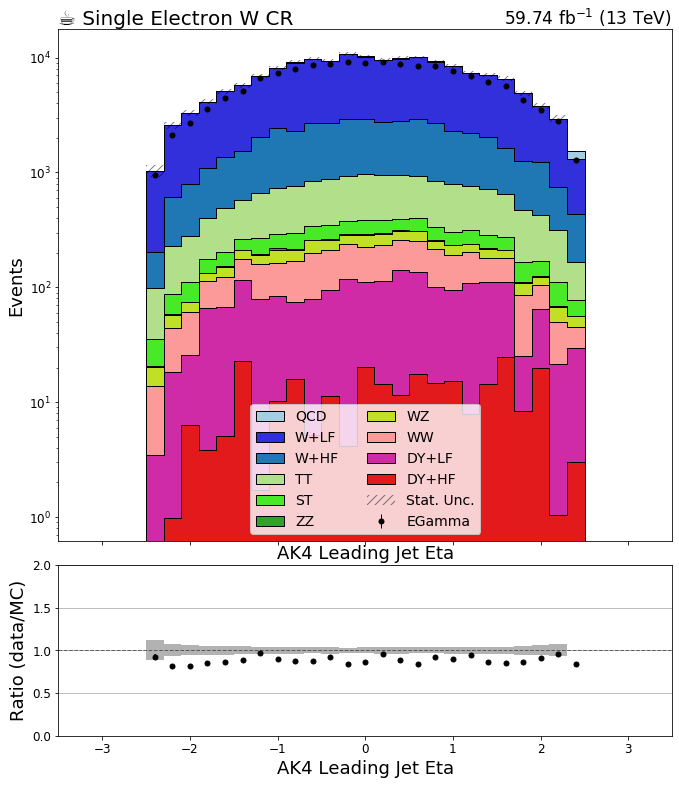

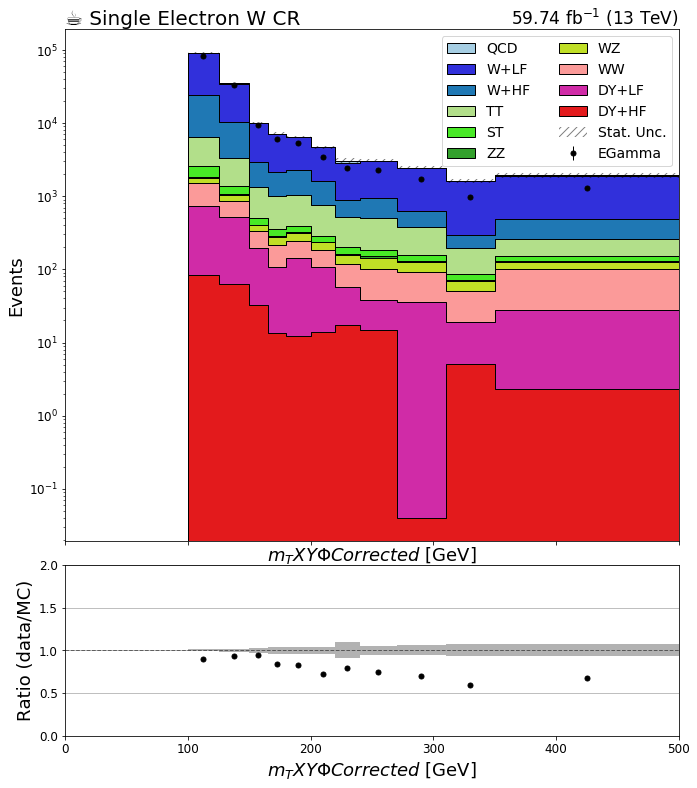

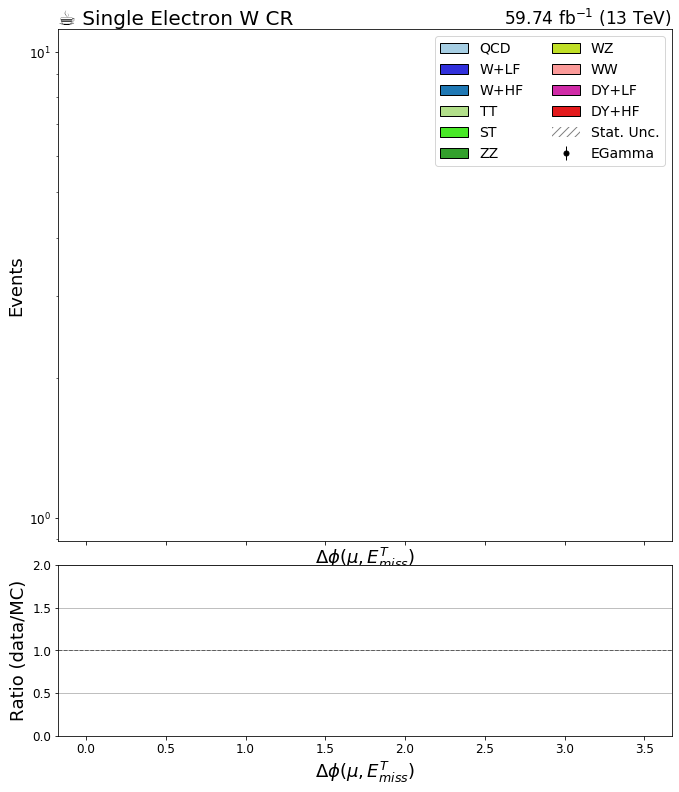

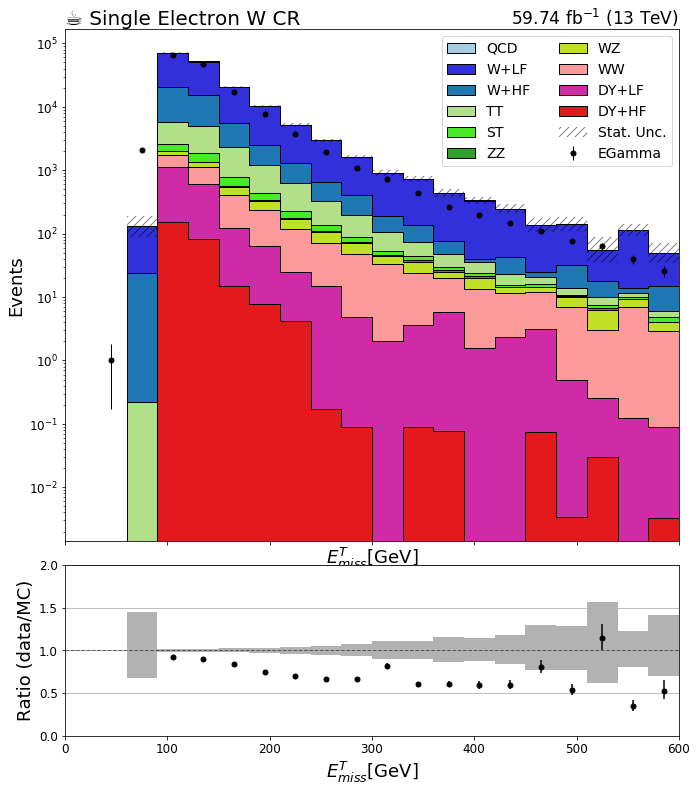

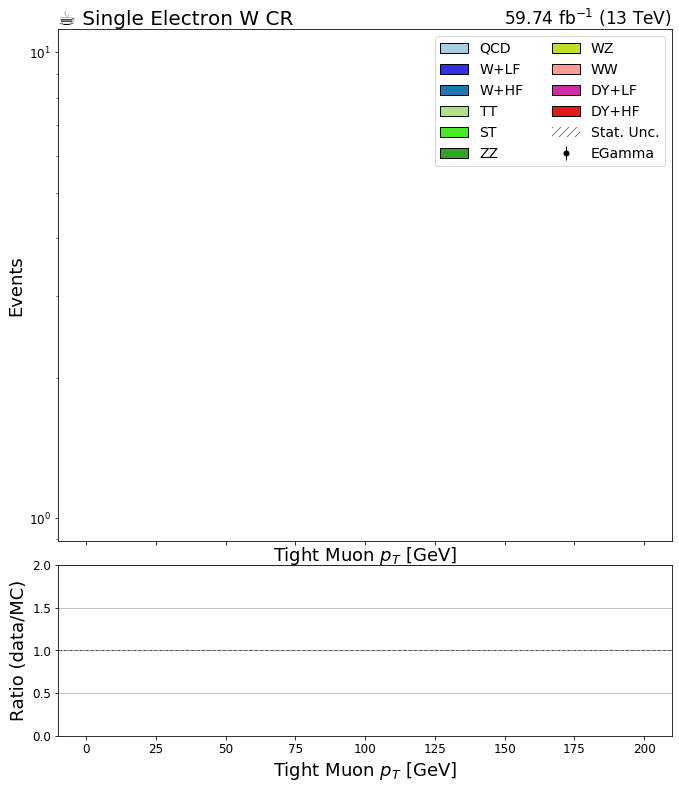

In [3]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

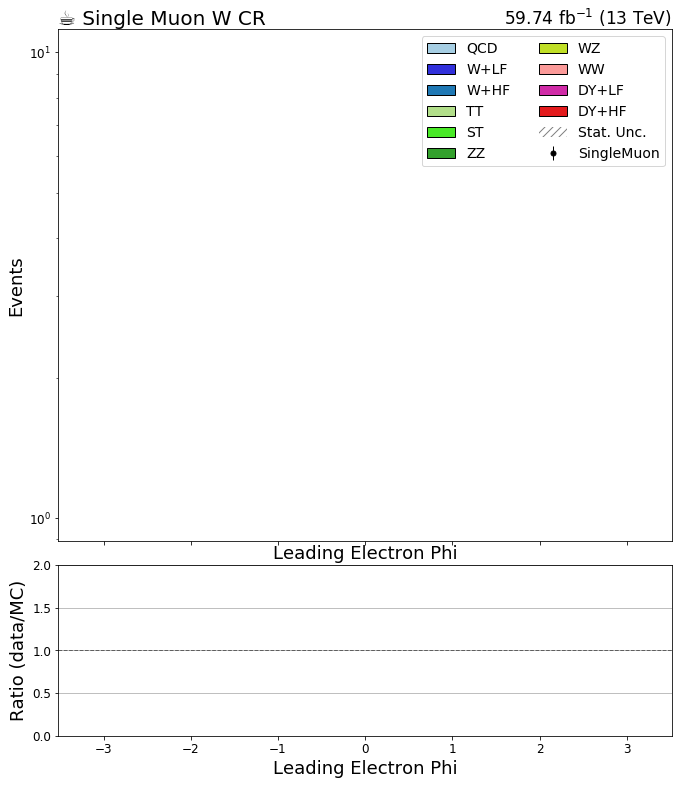

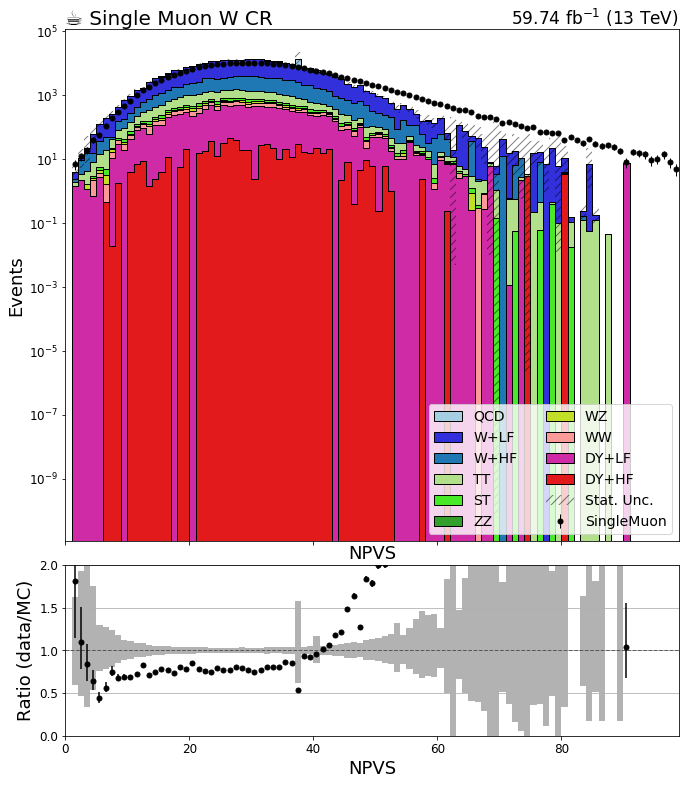

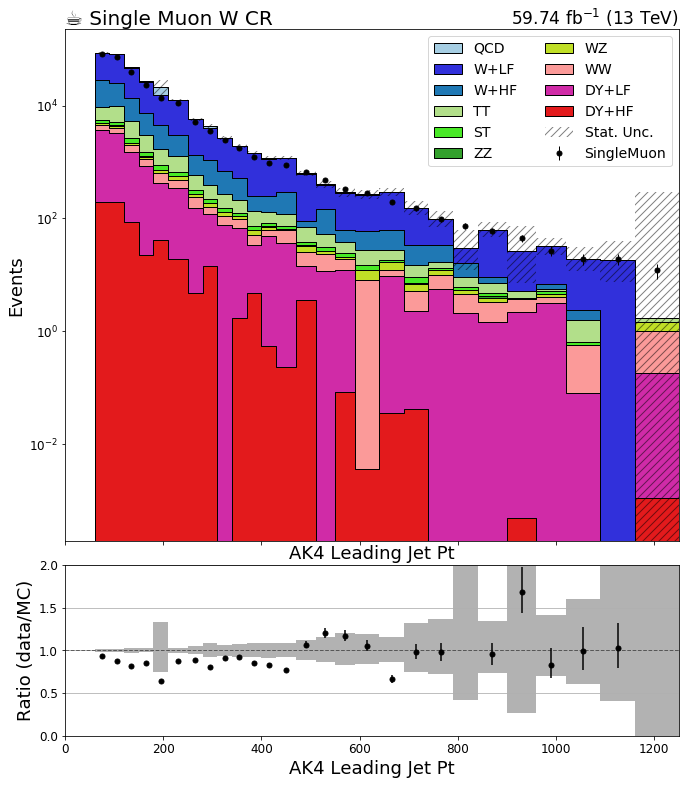

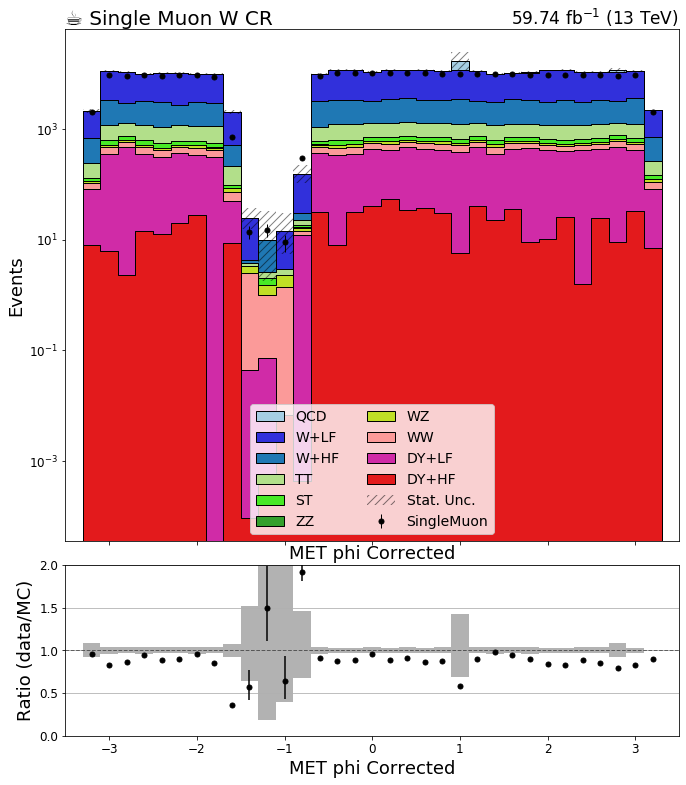

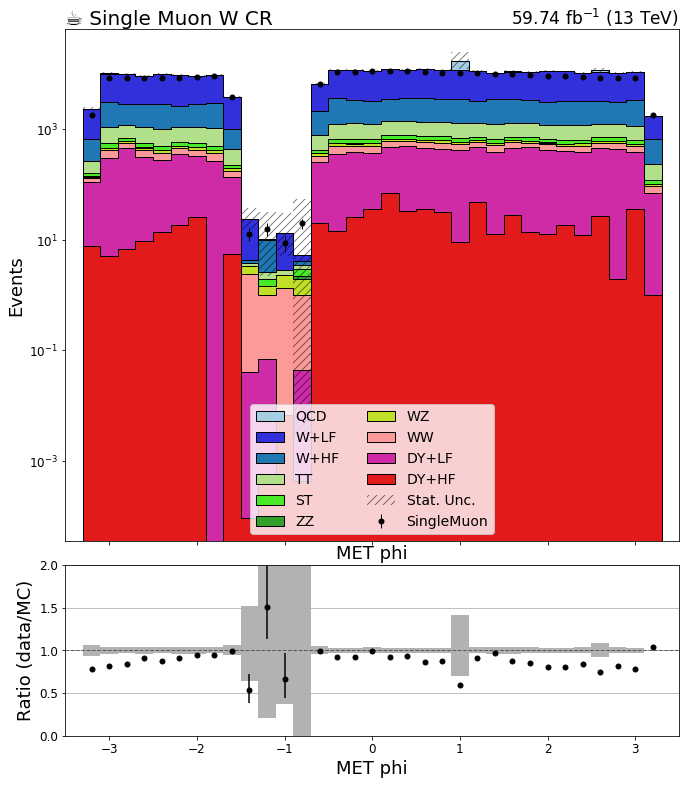

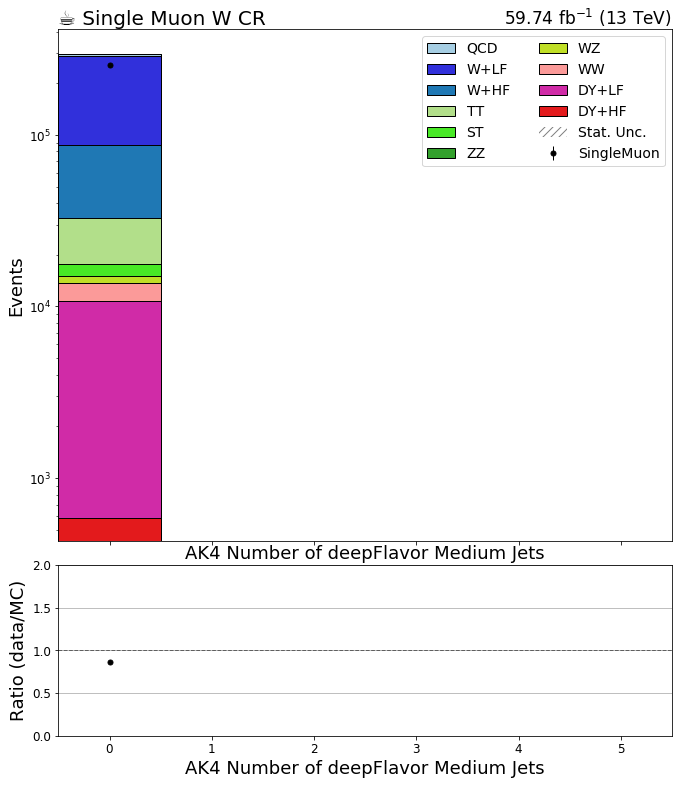

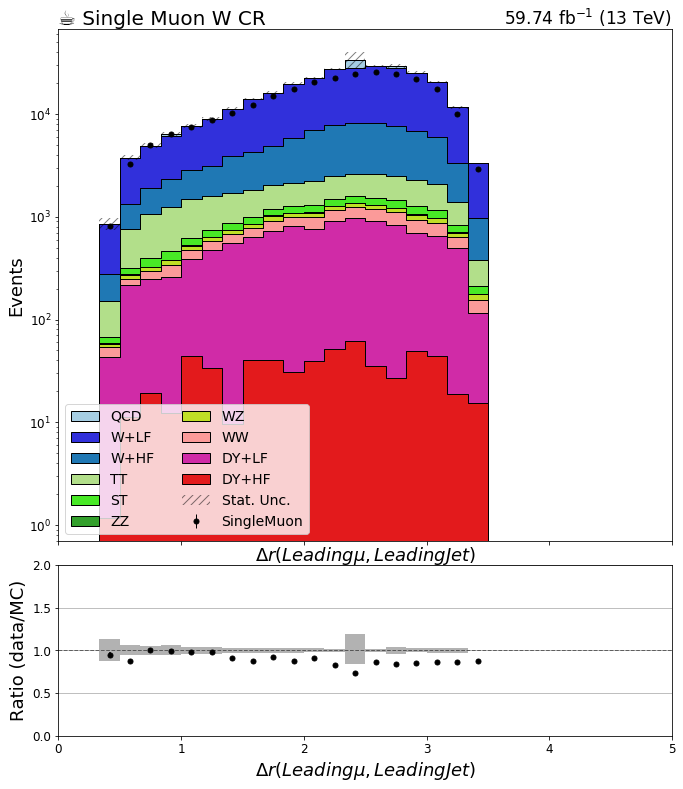

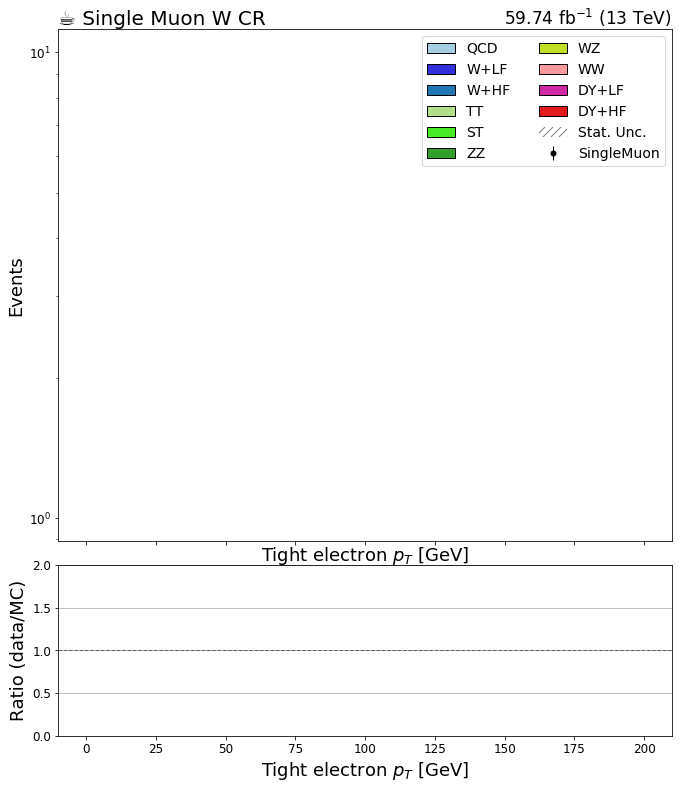

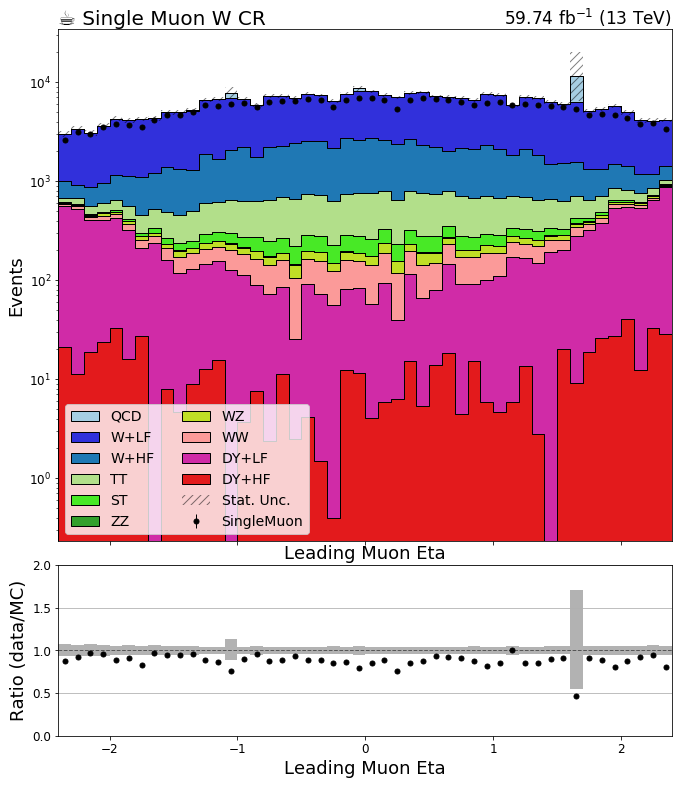

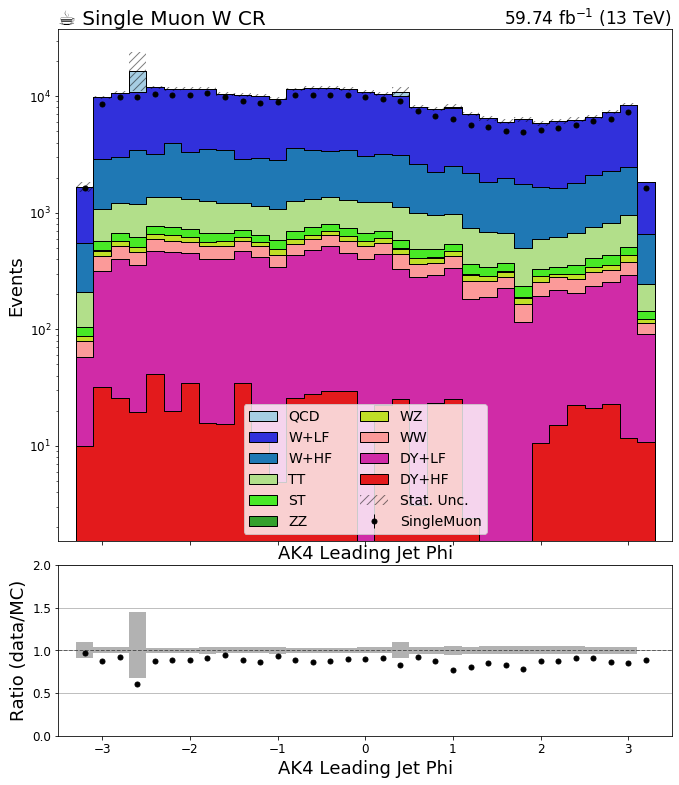

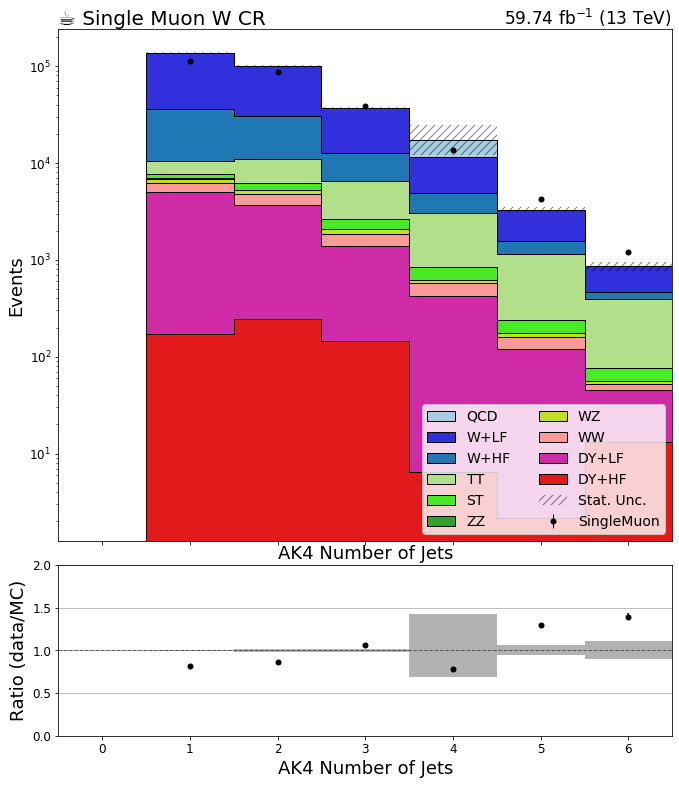

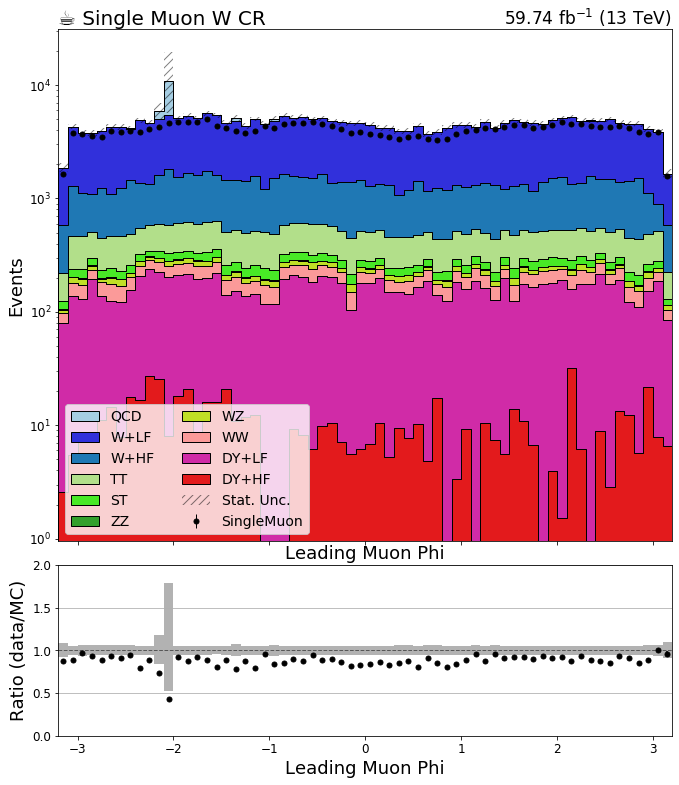

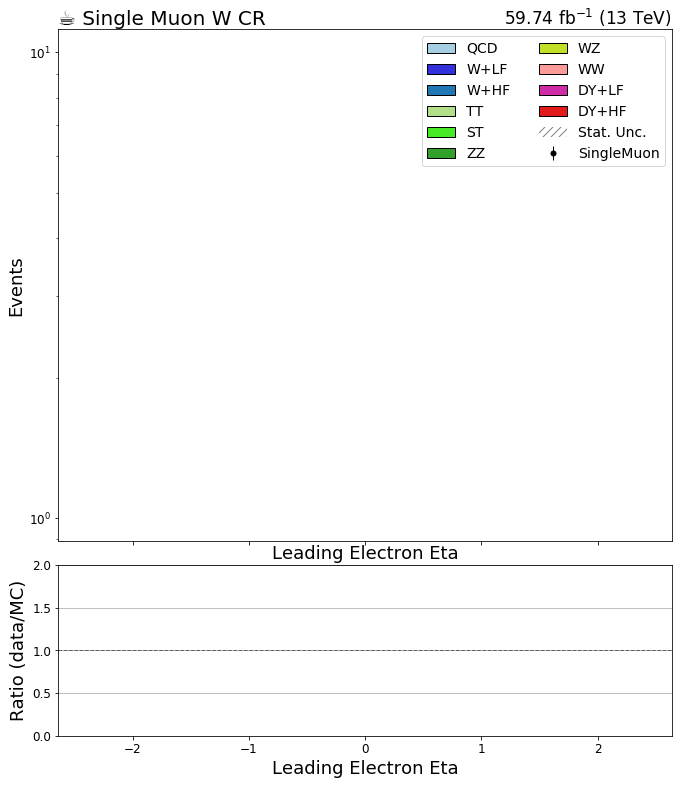

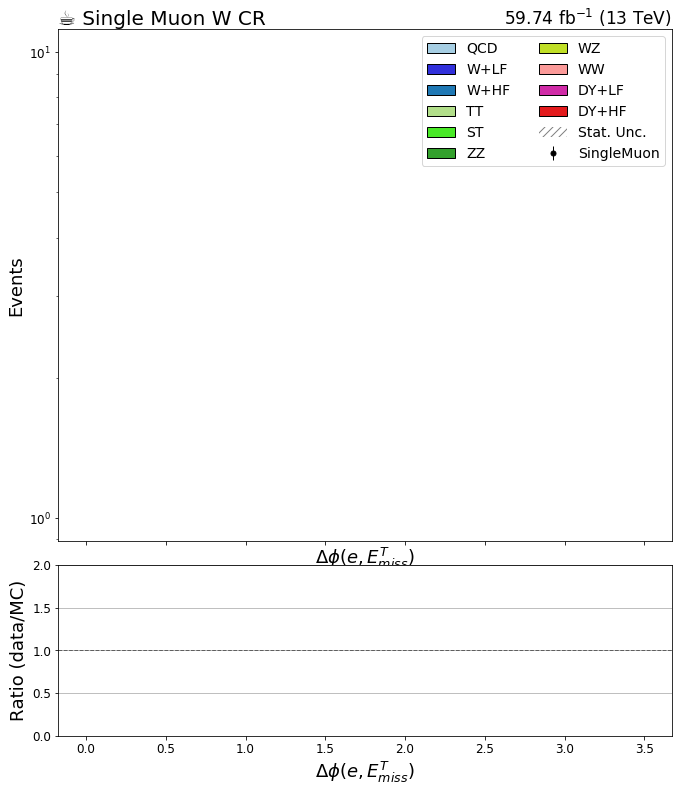

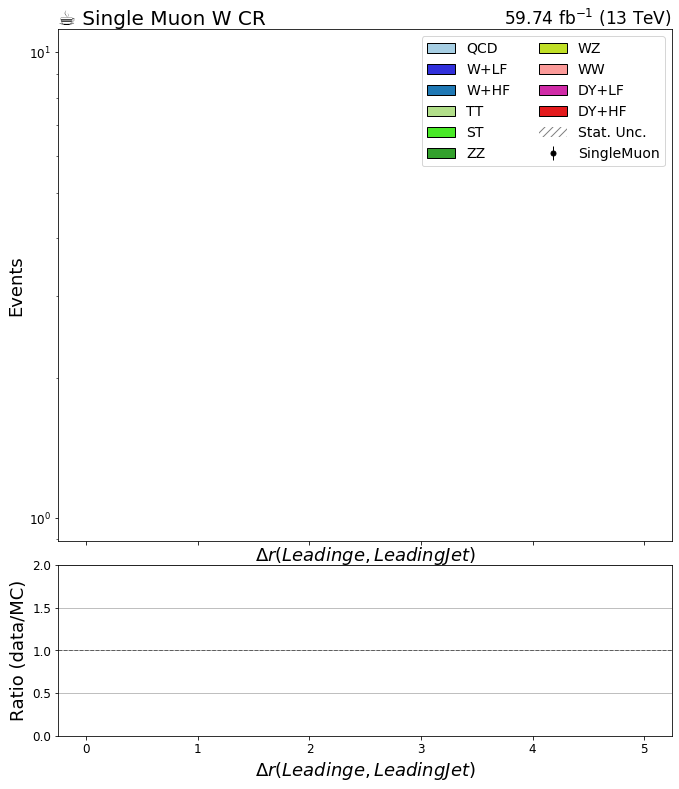

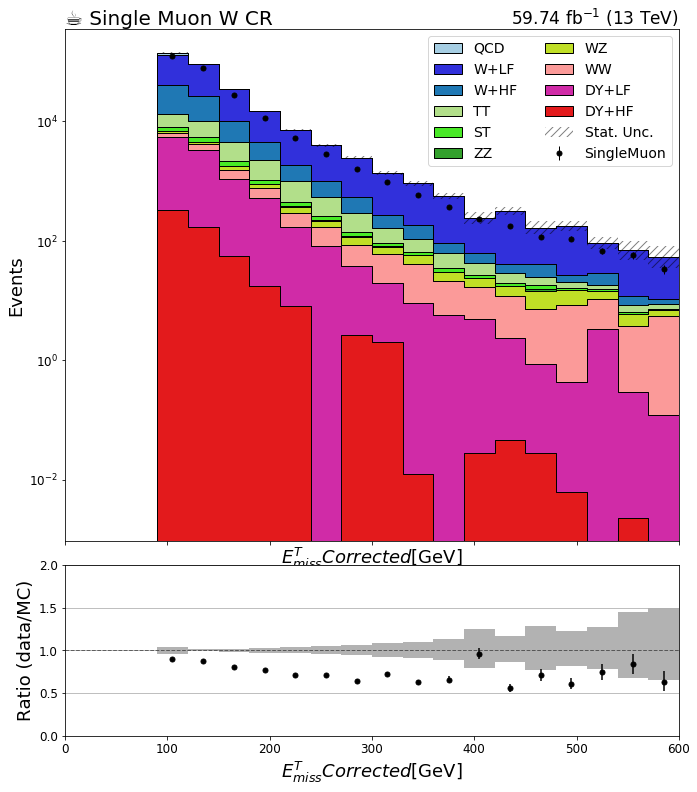

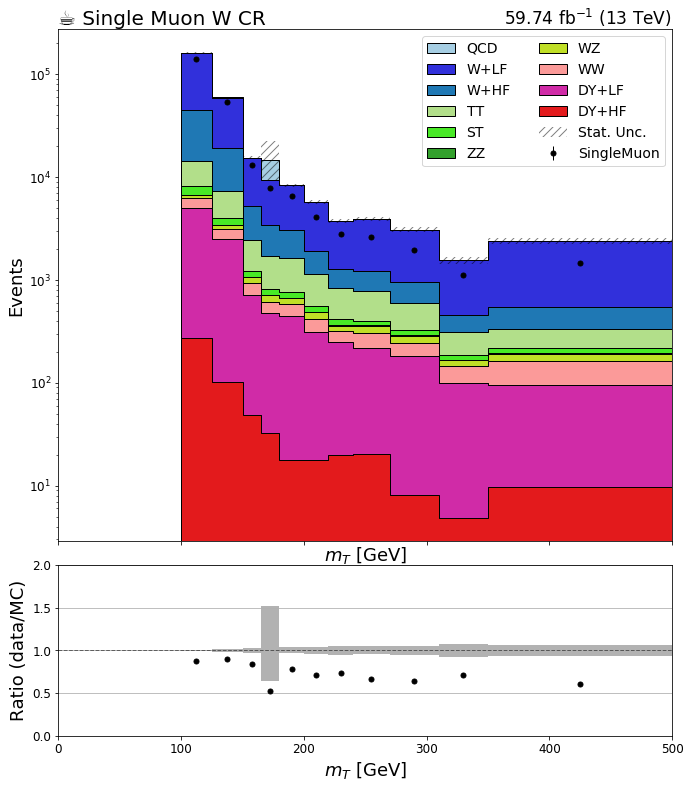

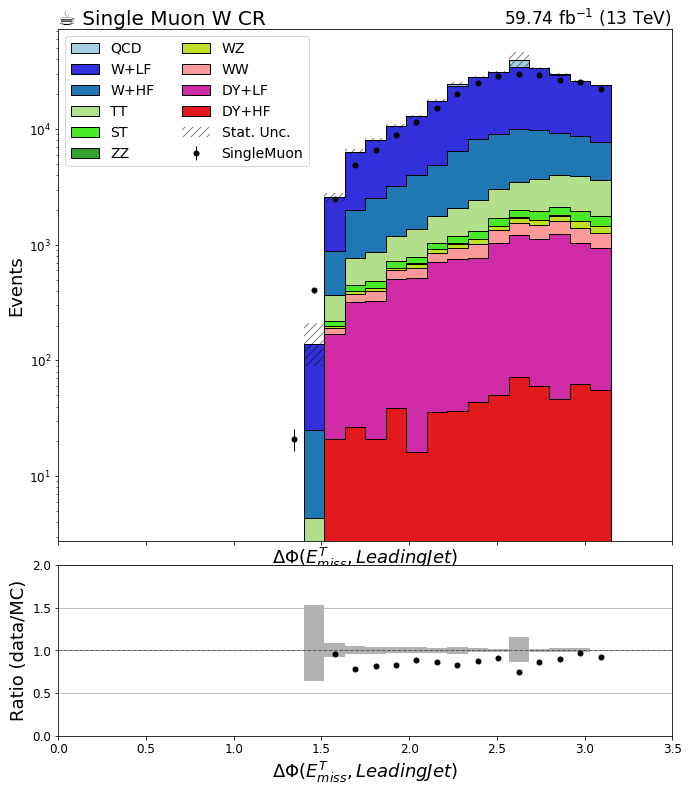

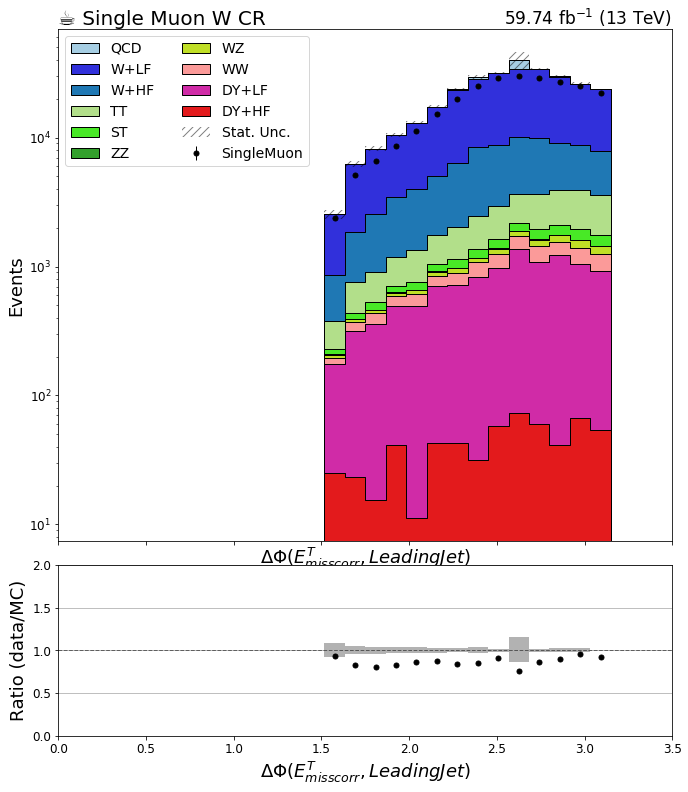

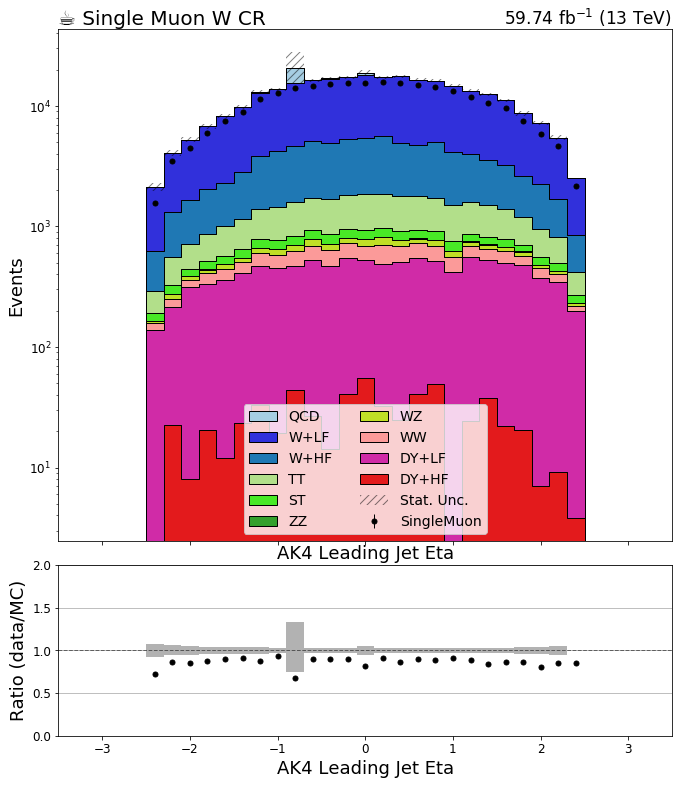

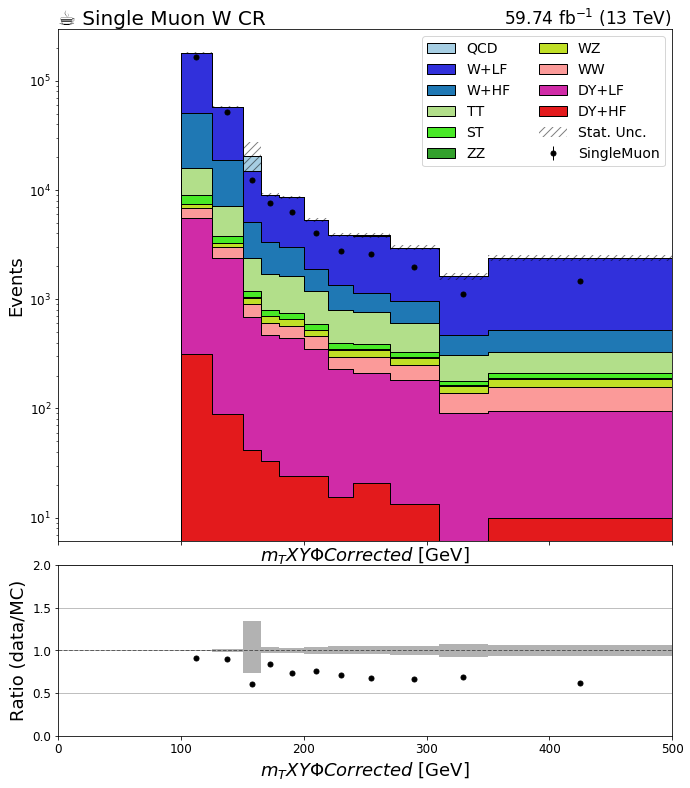

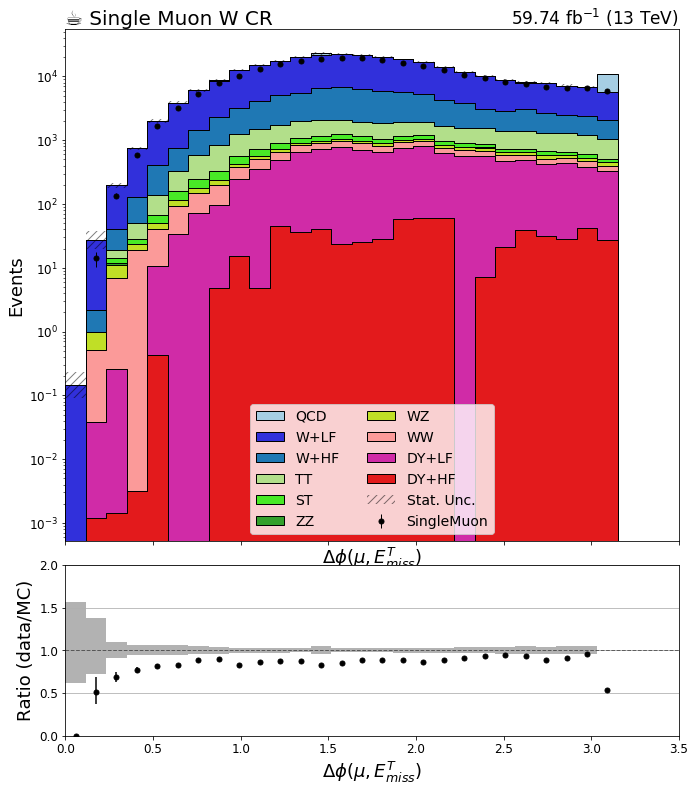

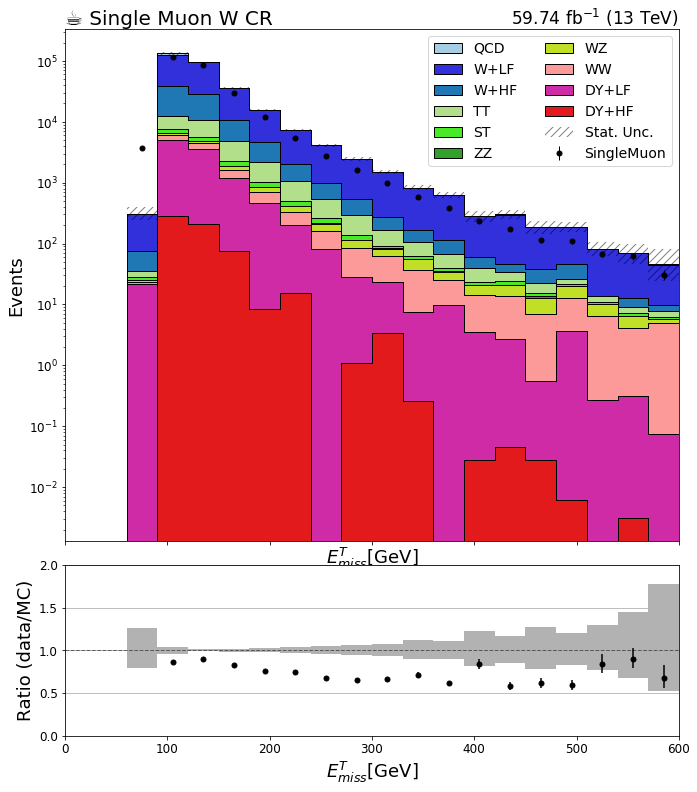

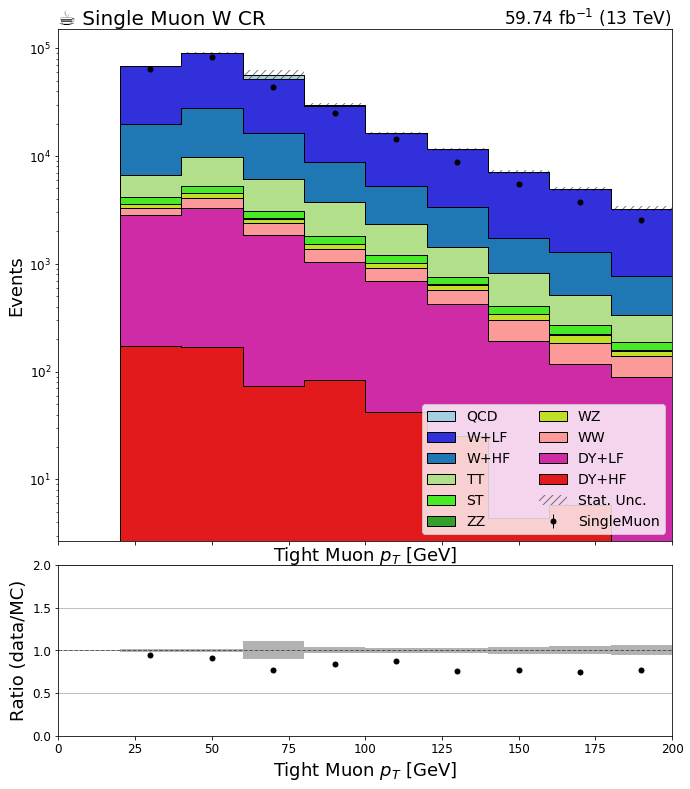

In [4]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

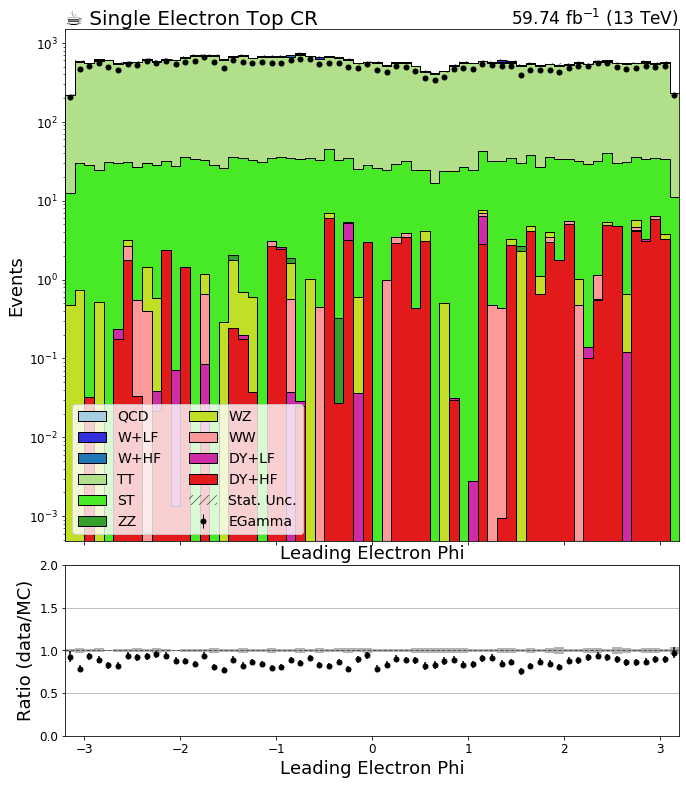

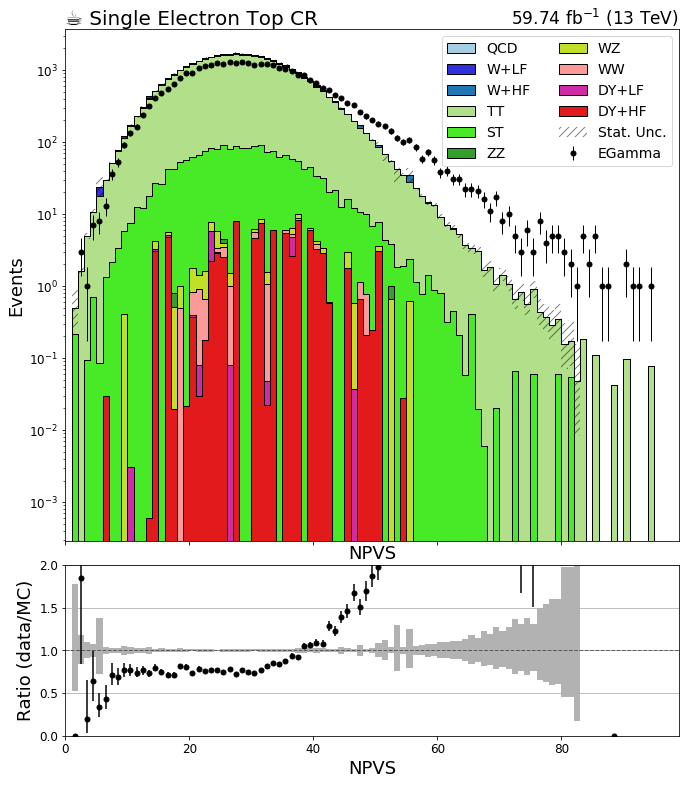

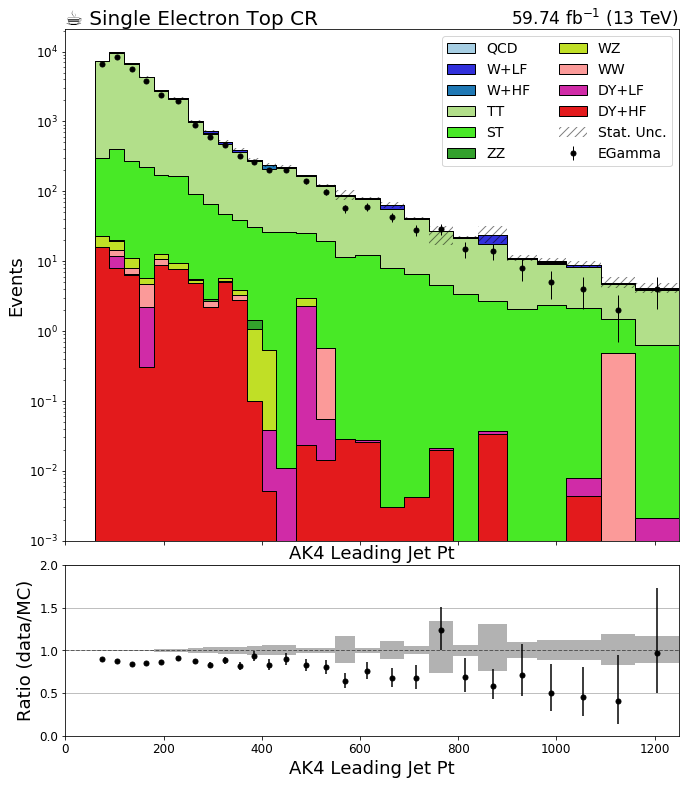

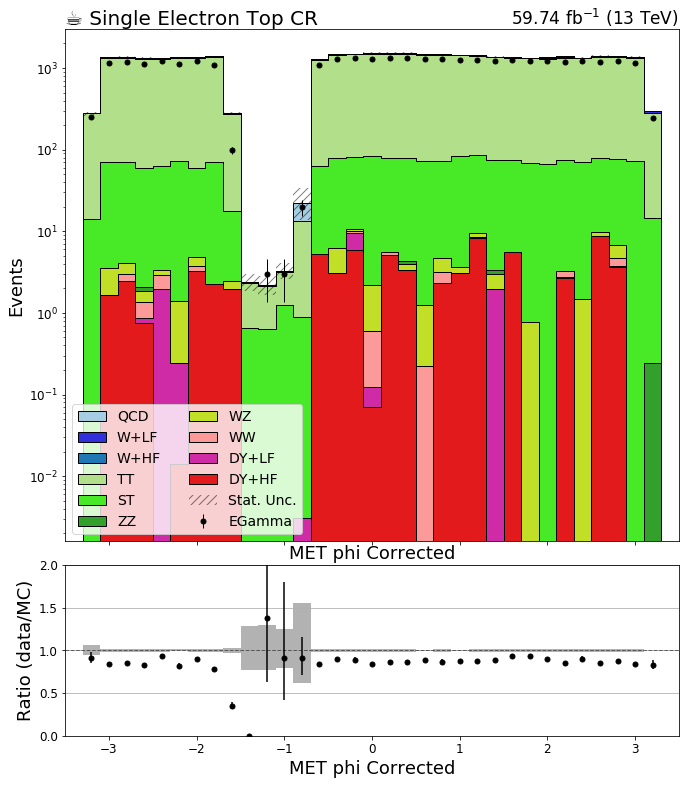

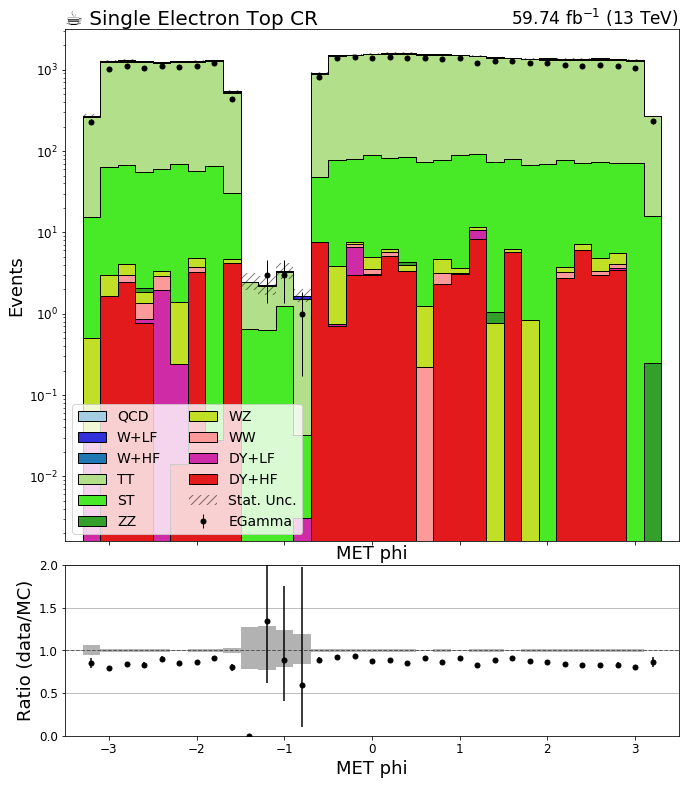

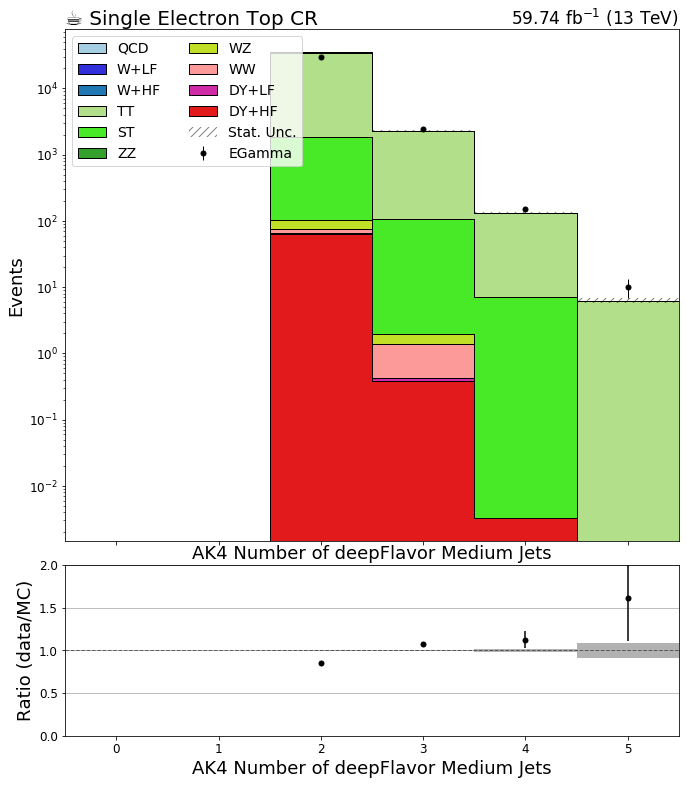

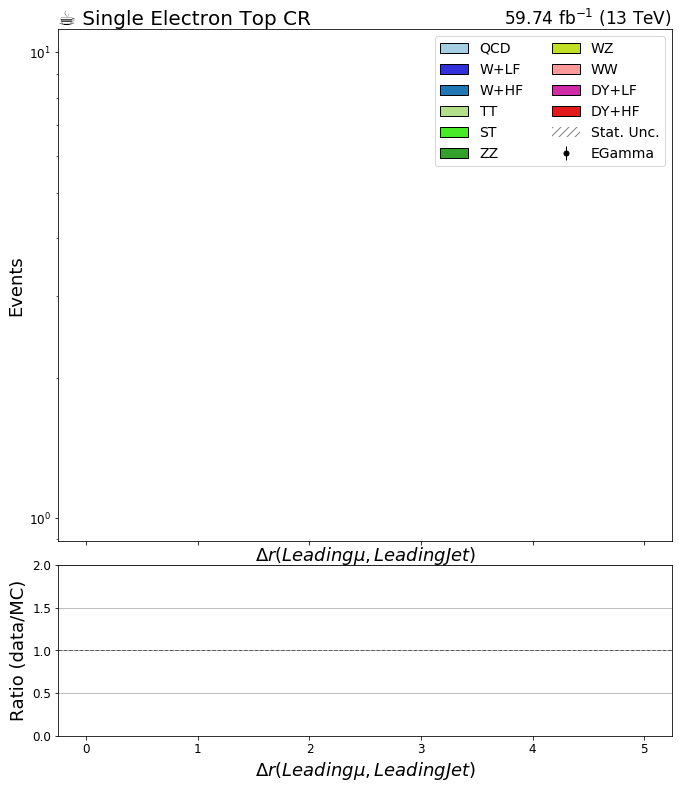

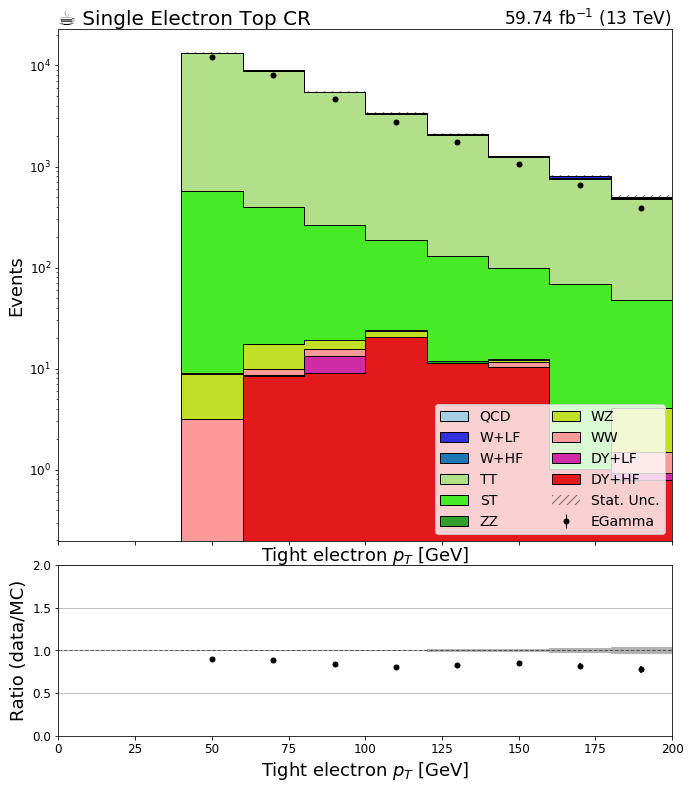

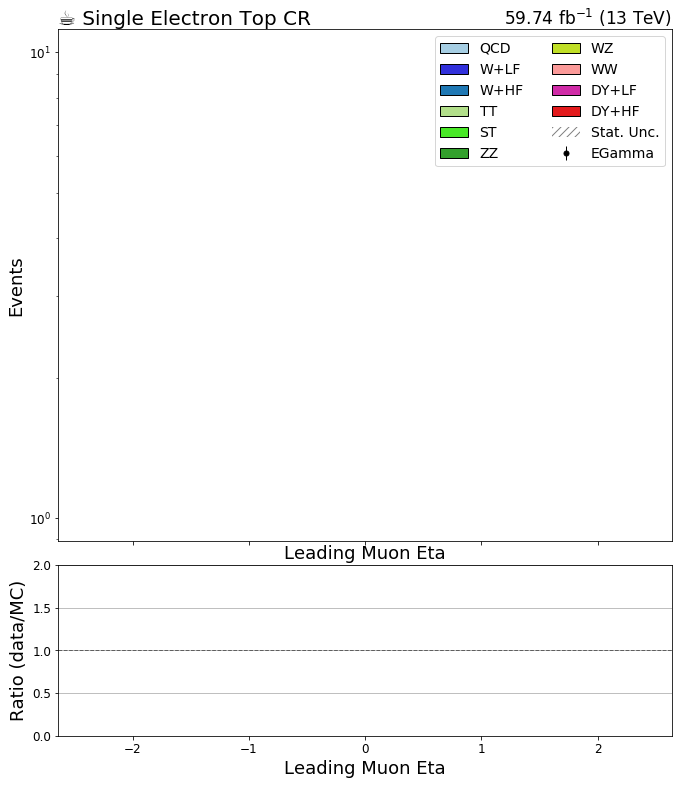

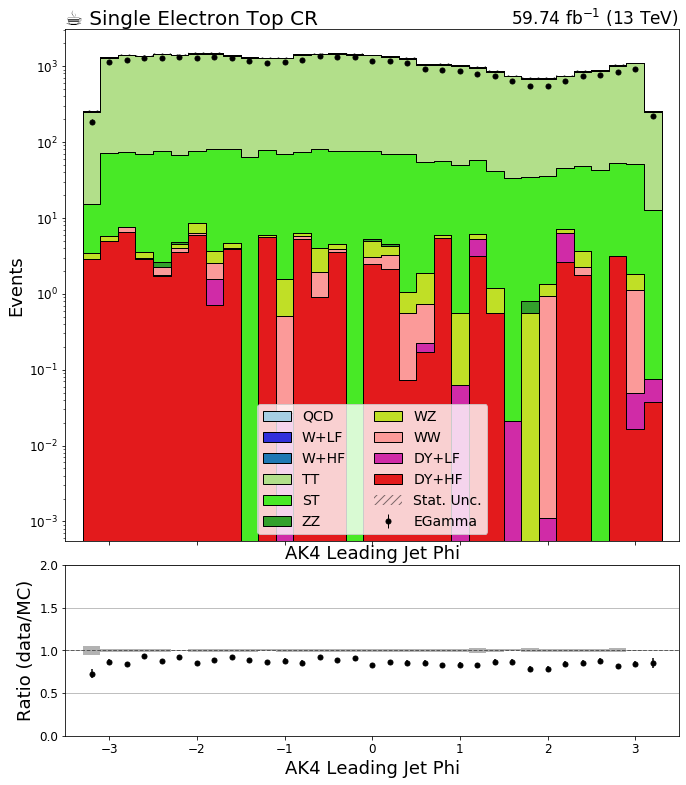

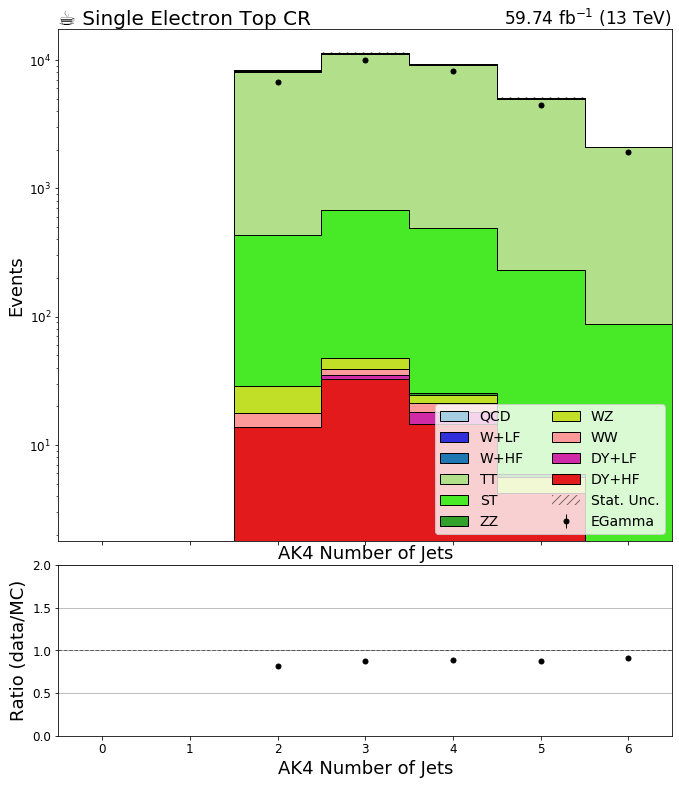

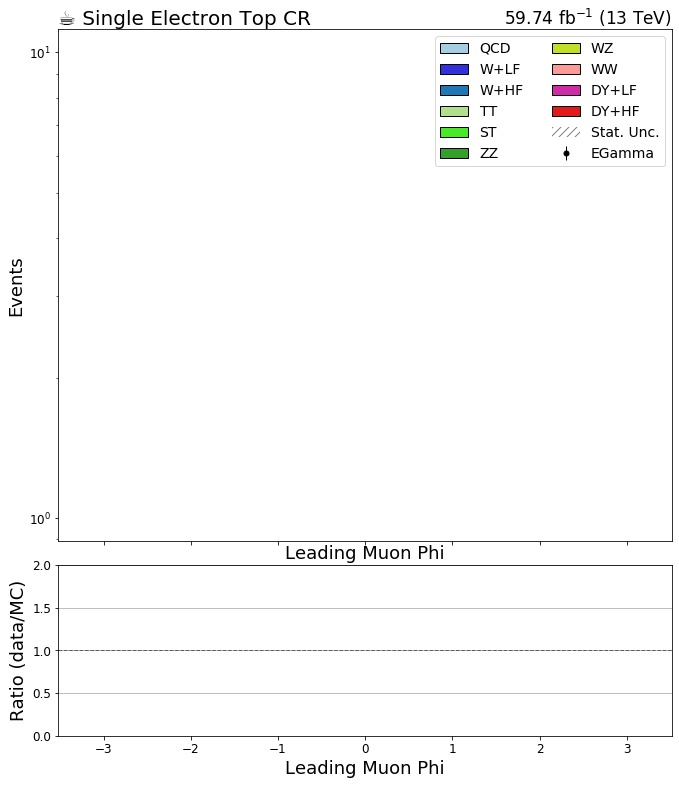

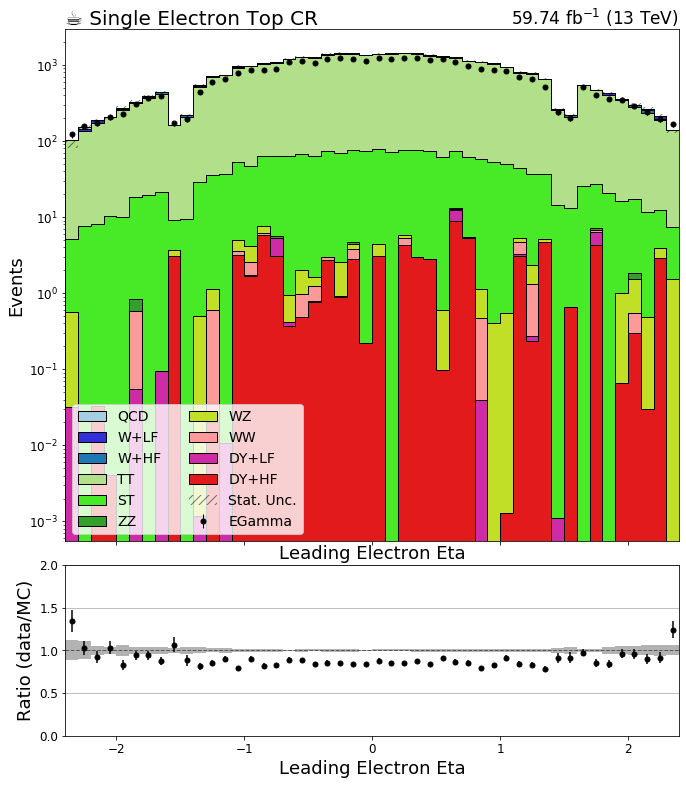

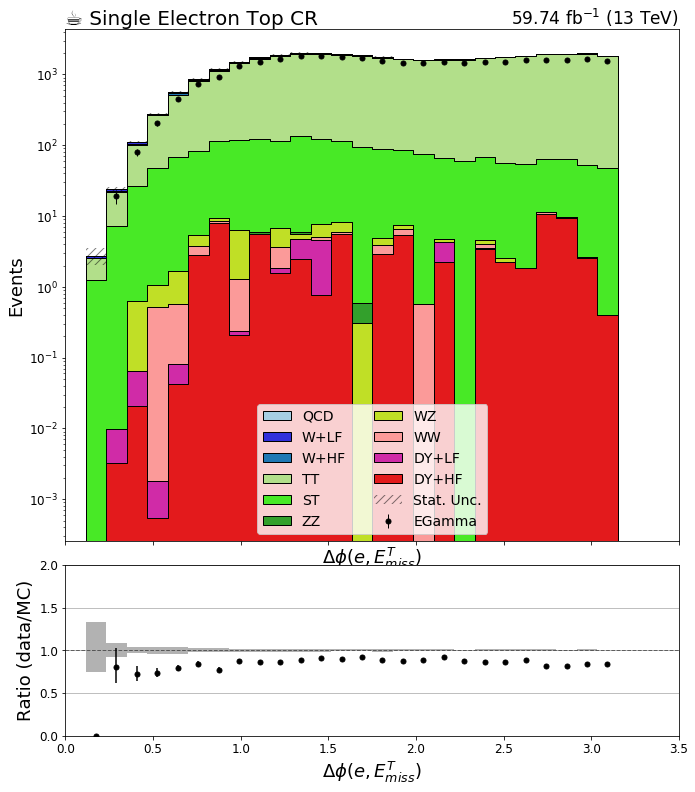

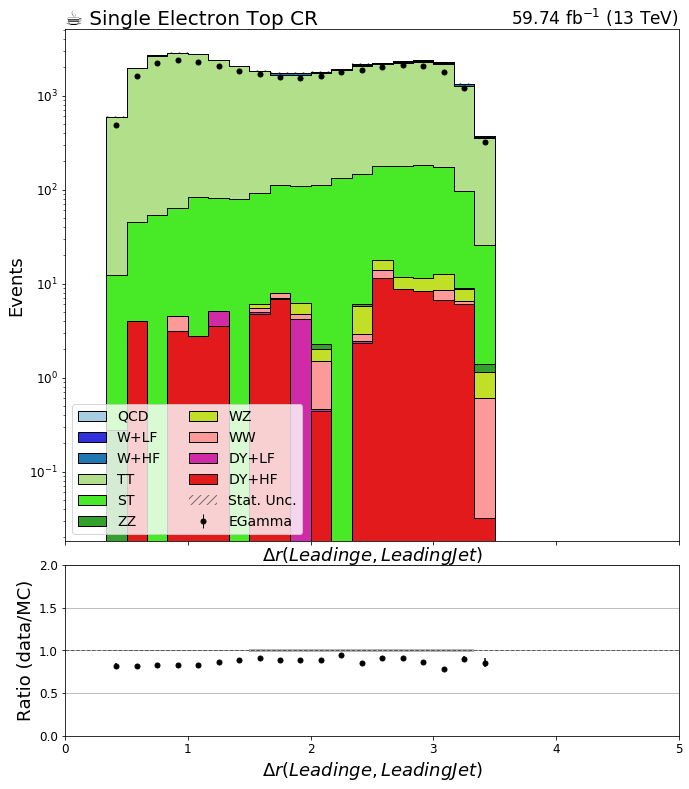

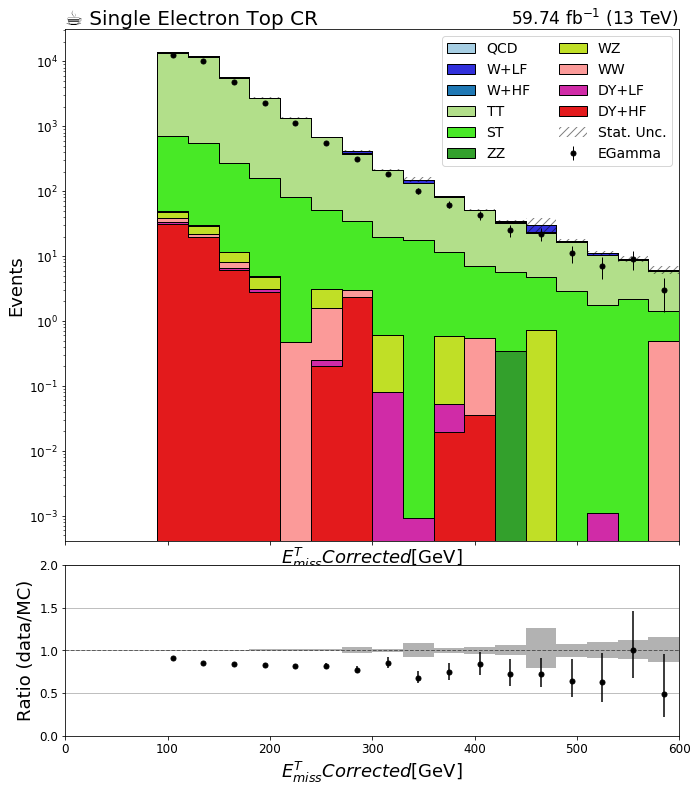

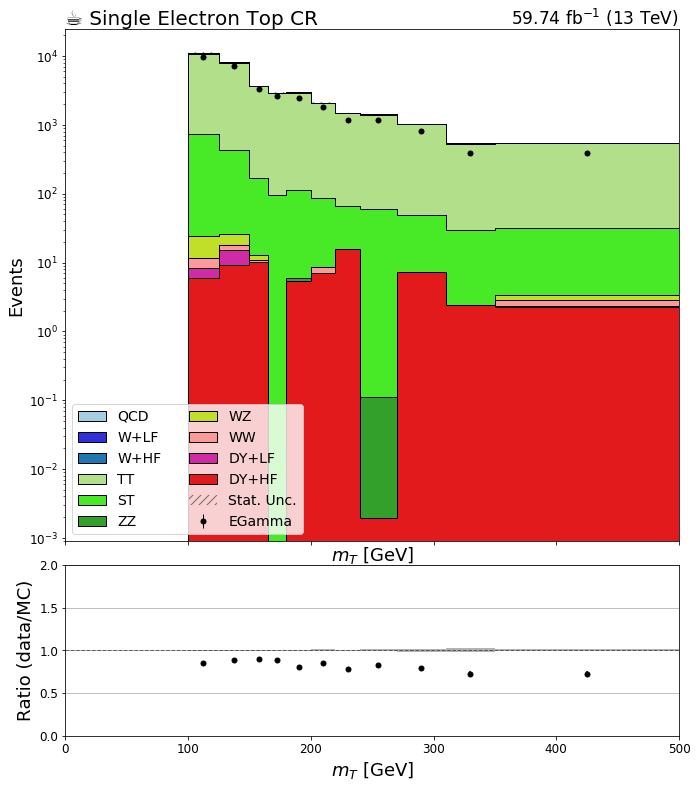

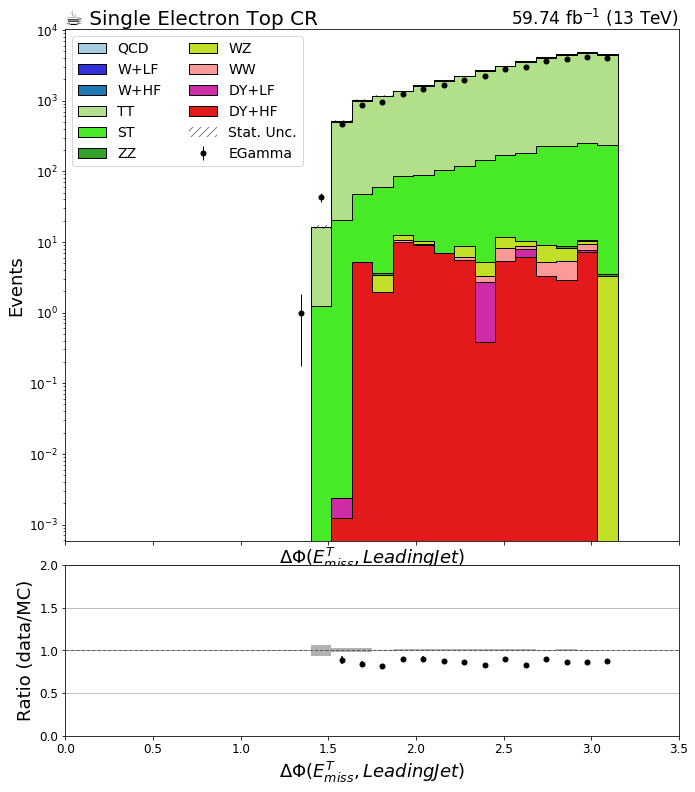

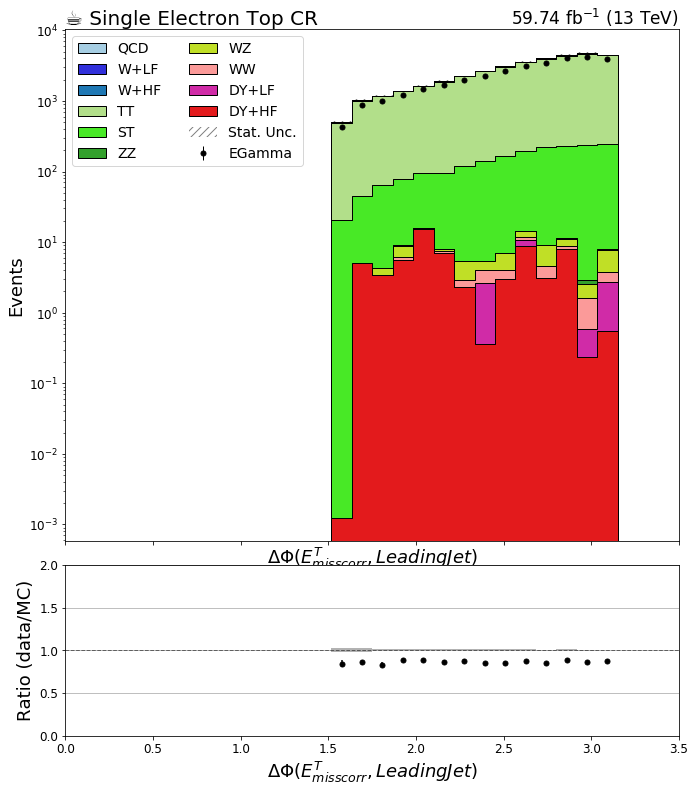

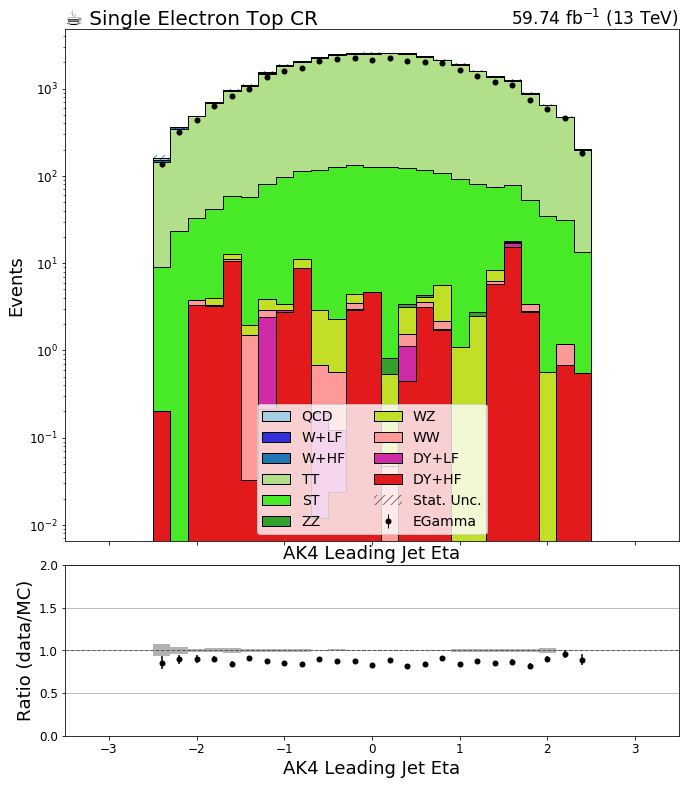

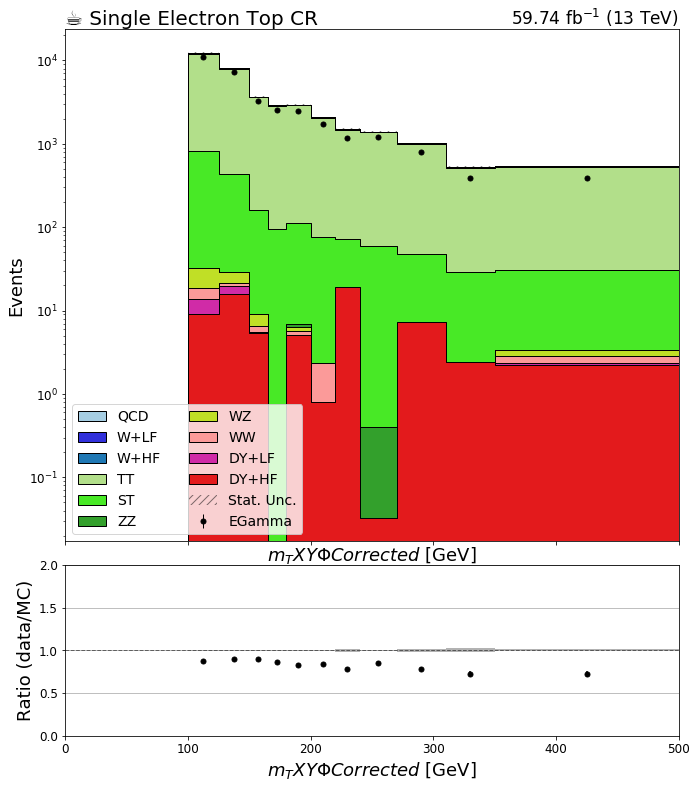

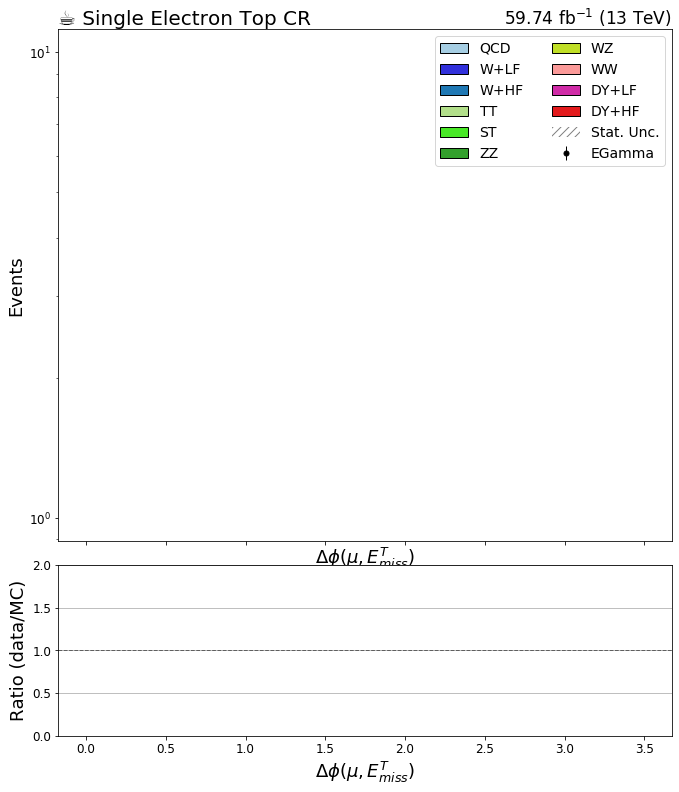

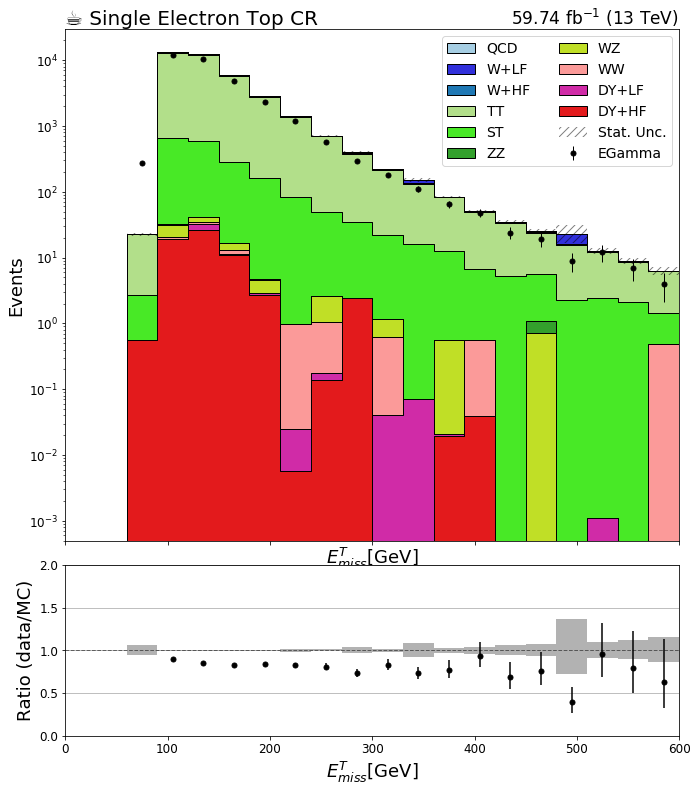

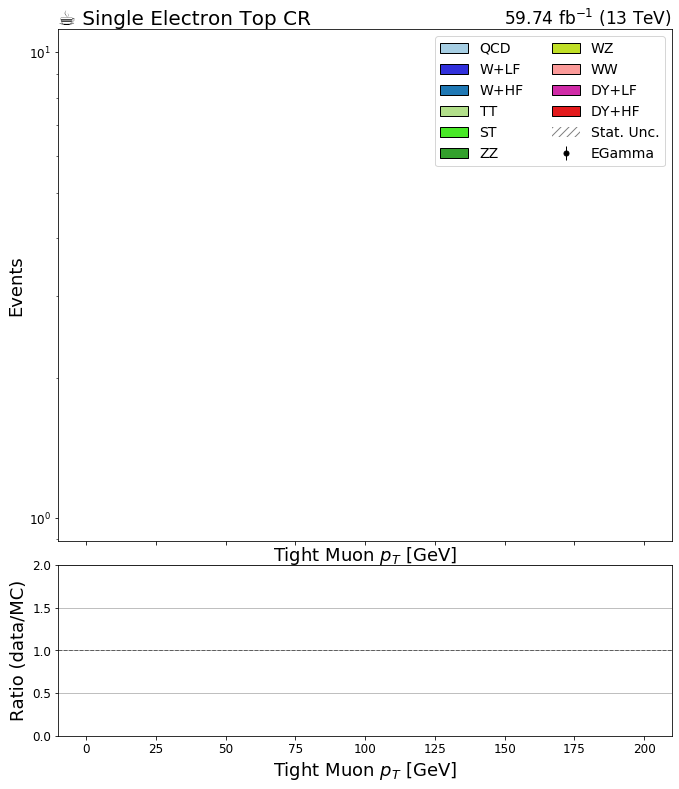

In [5]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

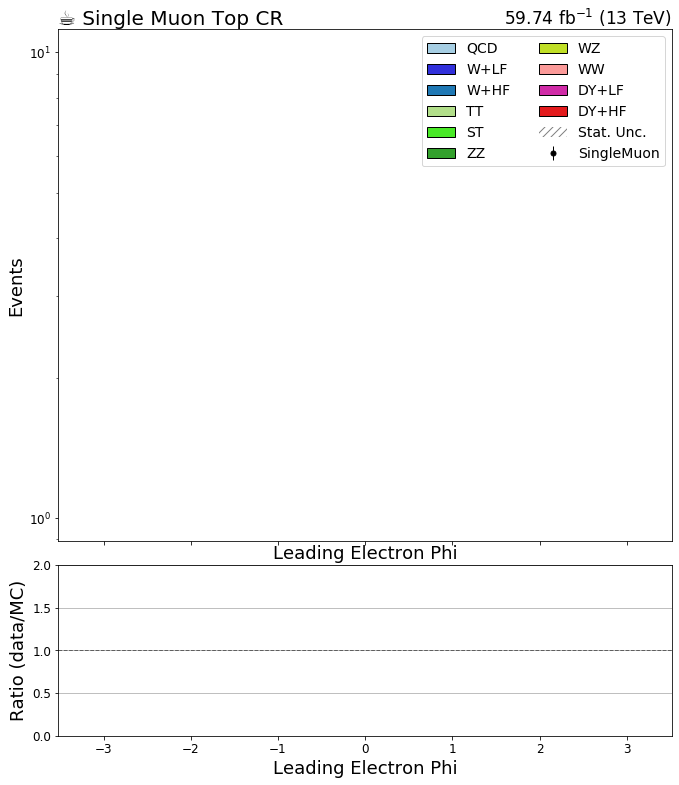

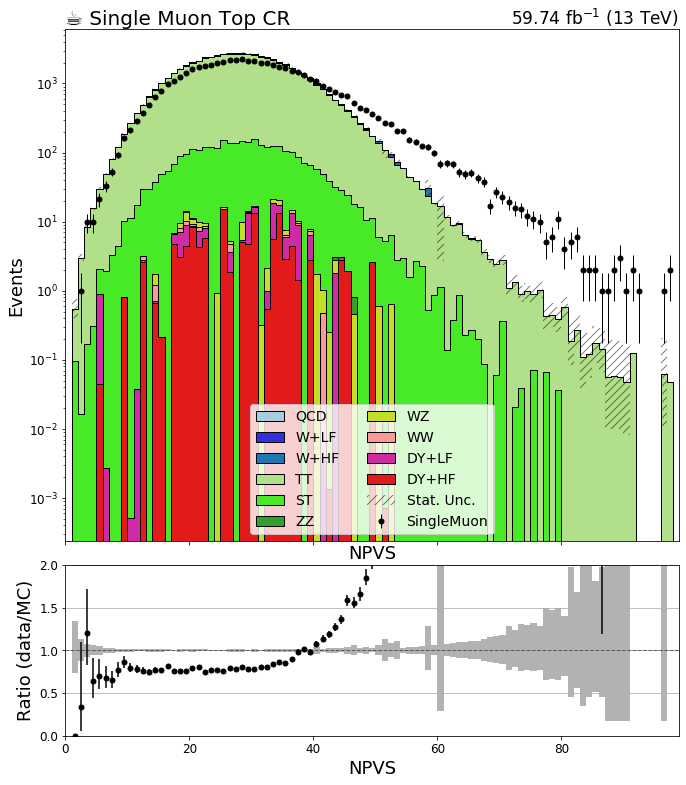

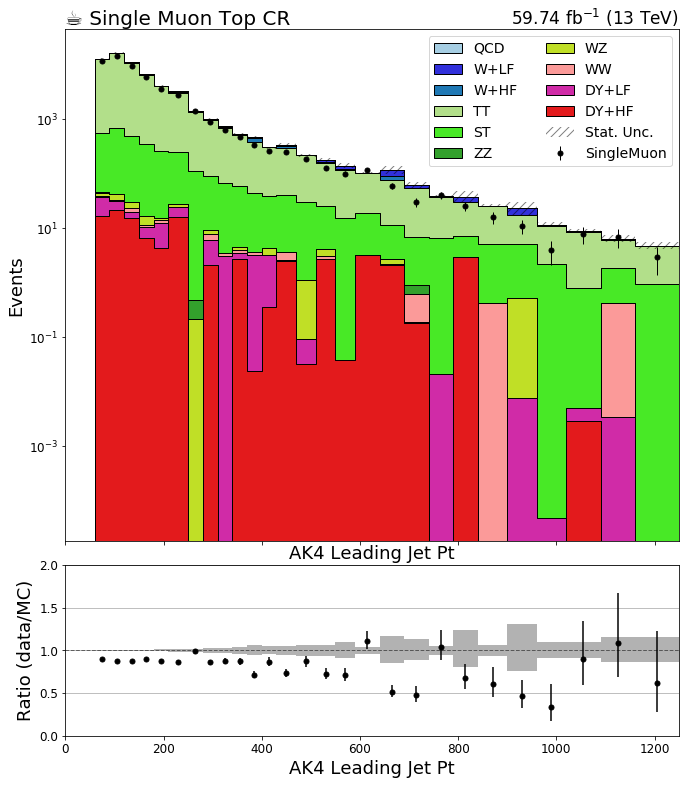

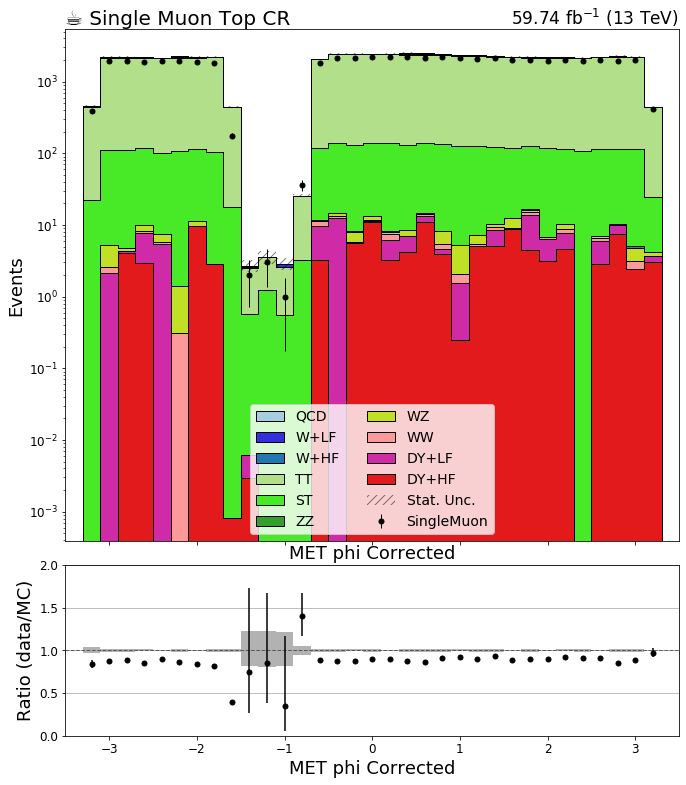

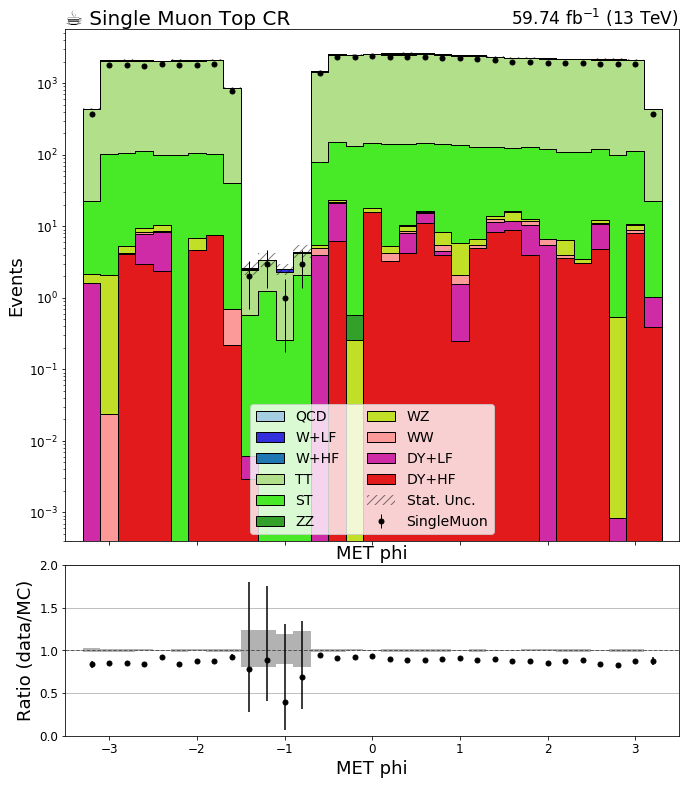

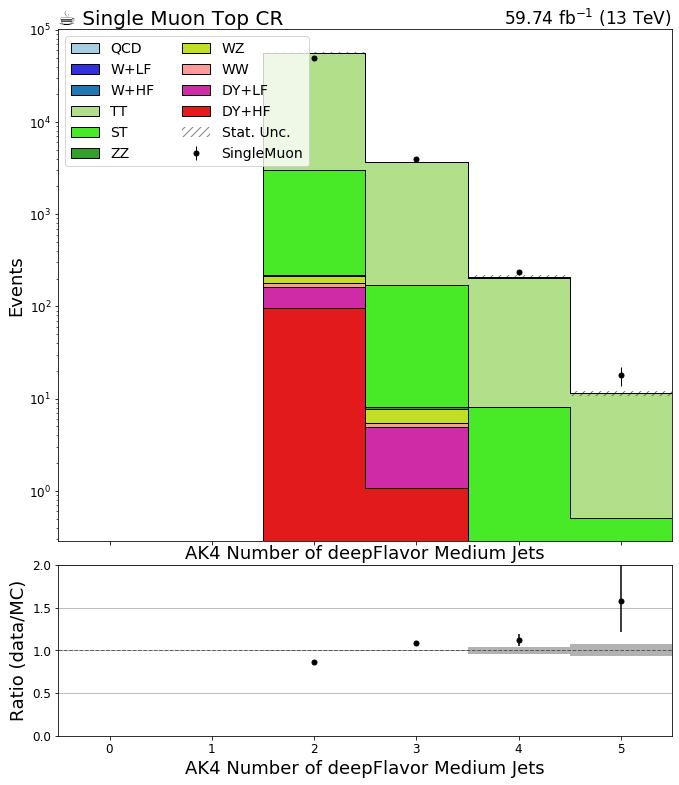

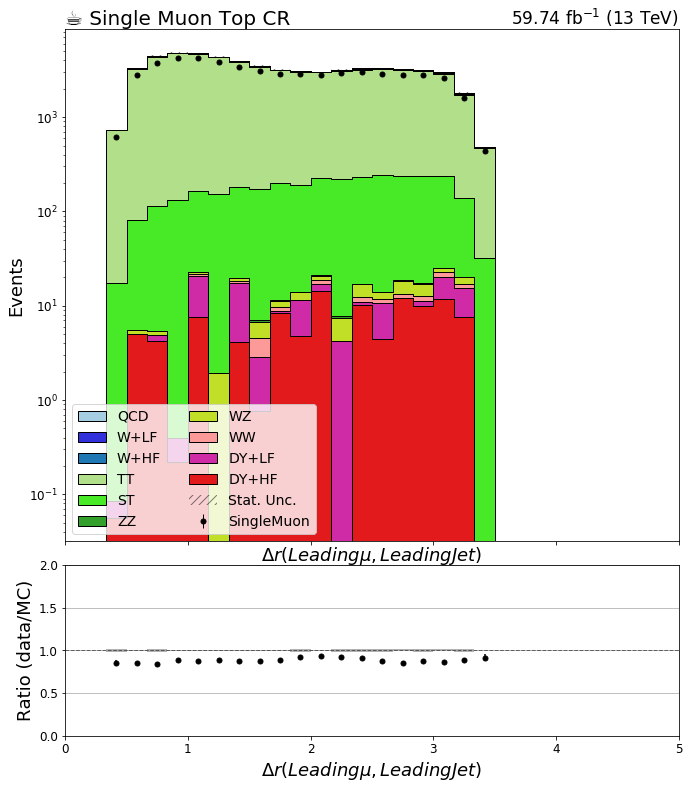

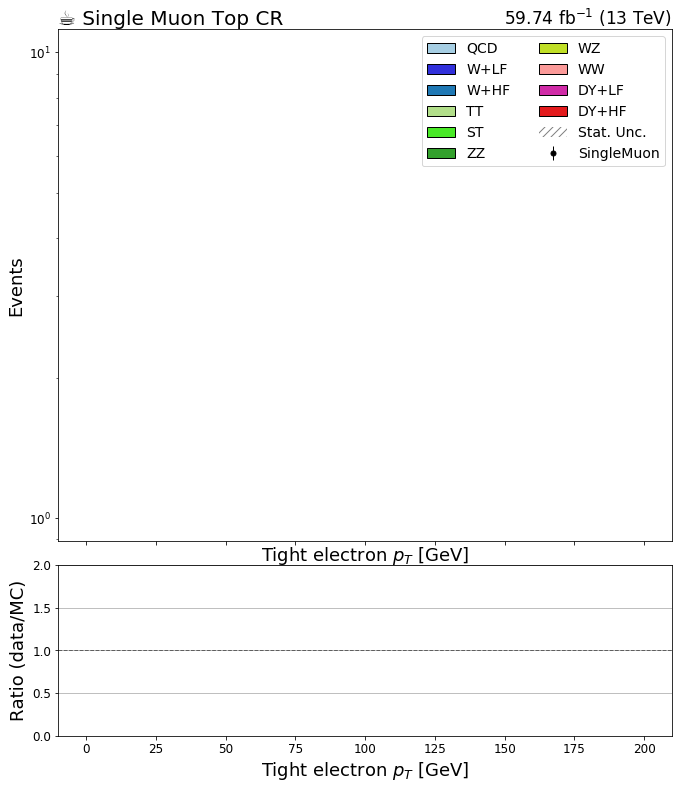

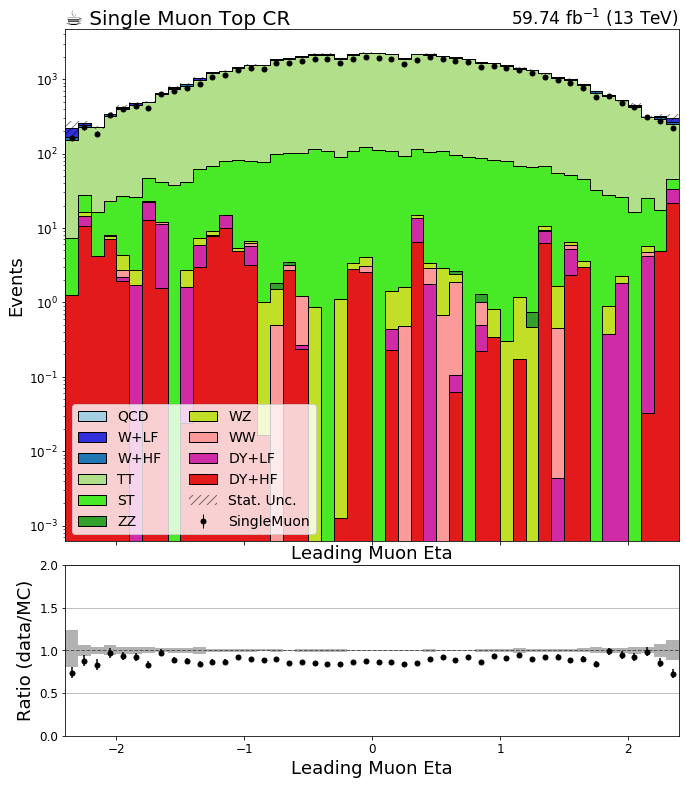

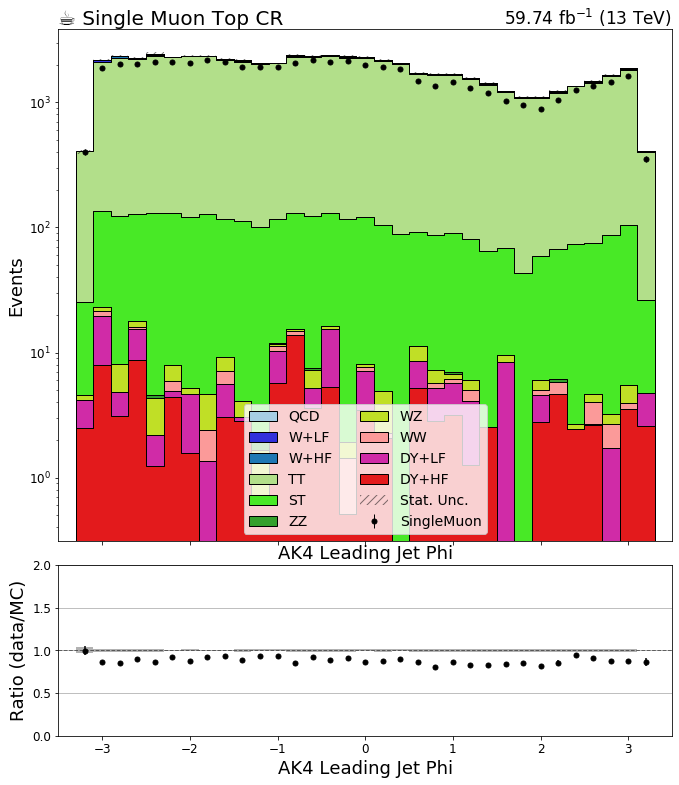

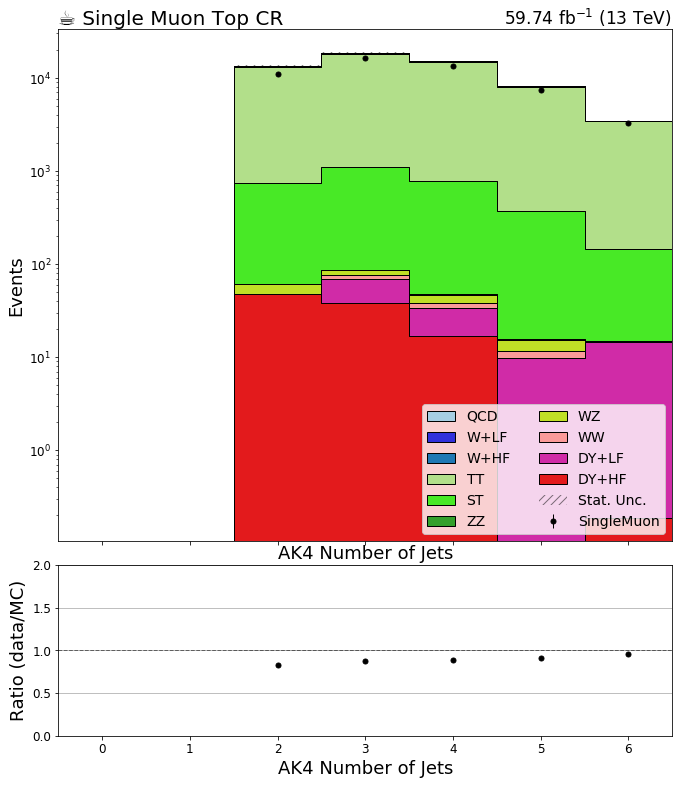

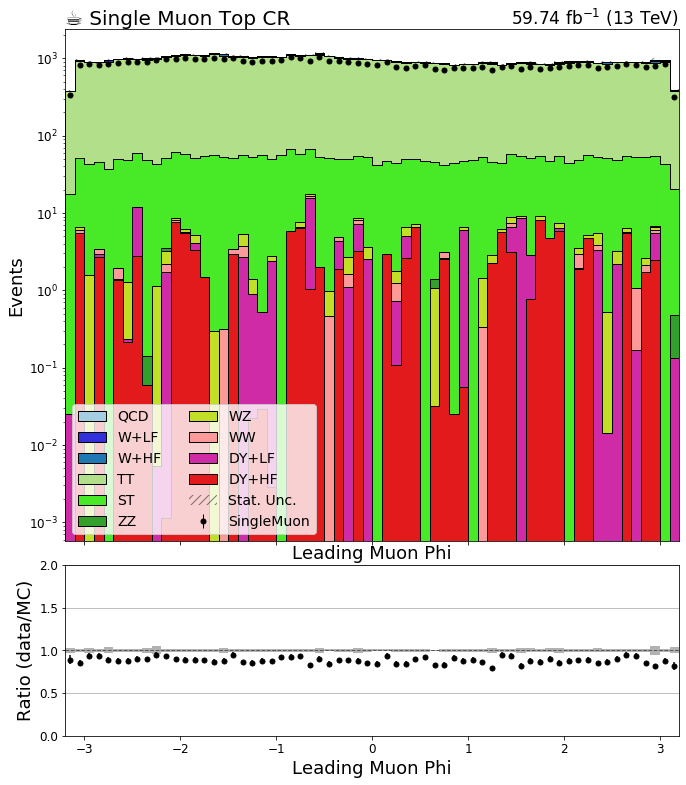

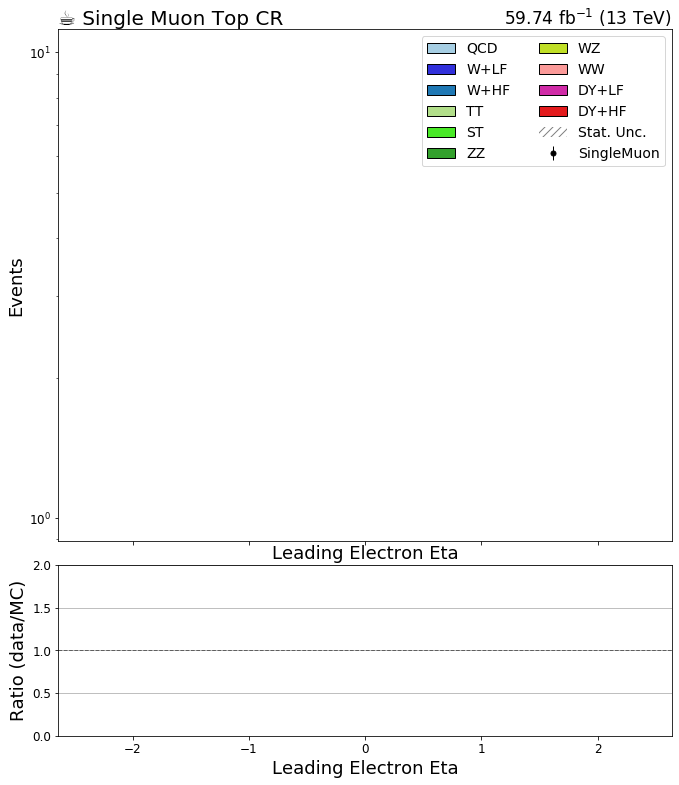

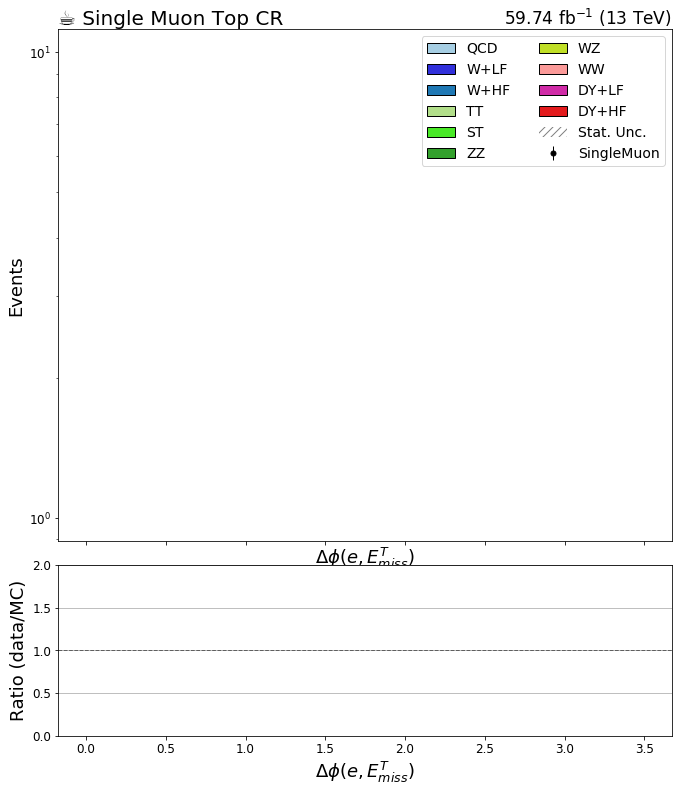

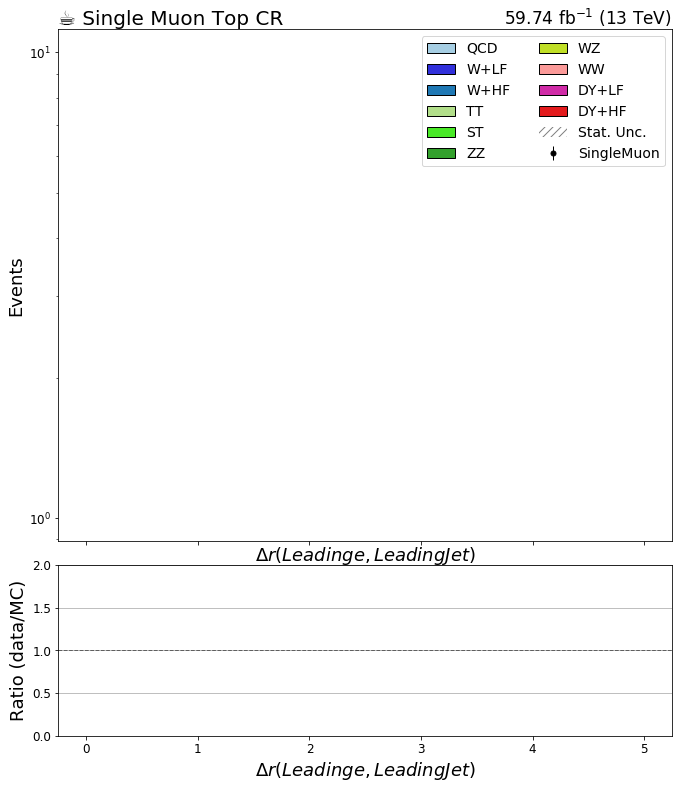

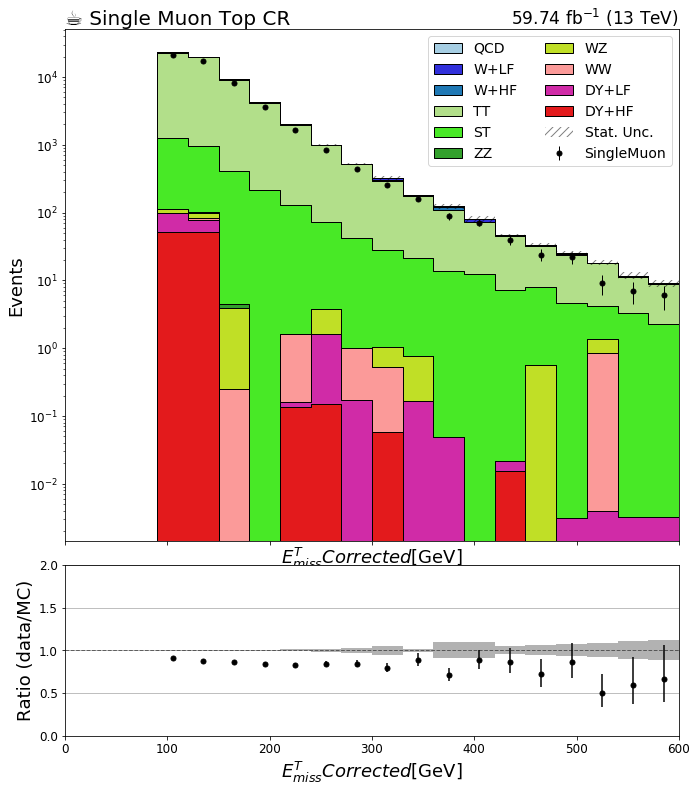

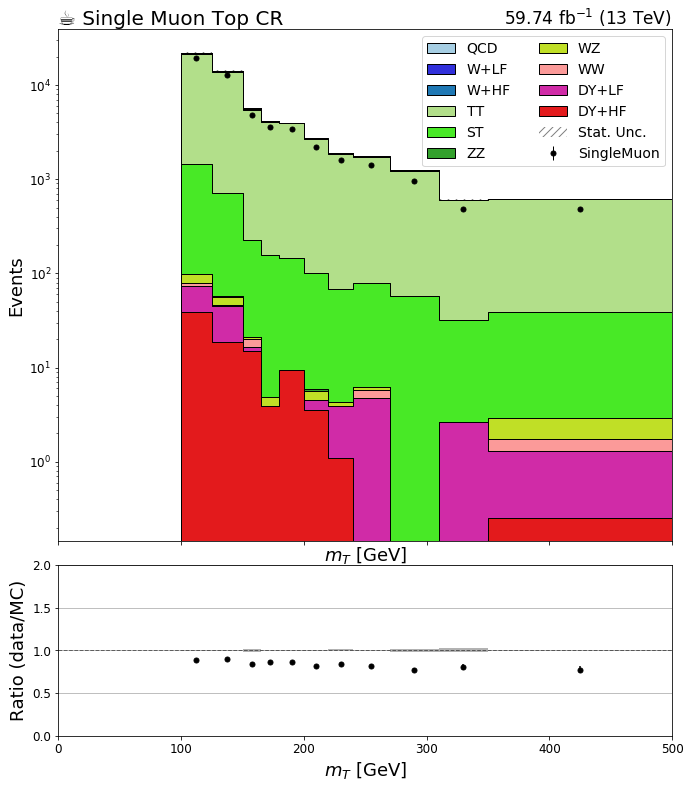

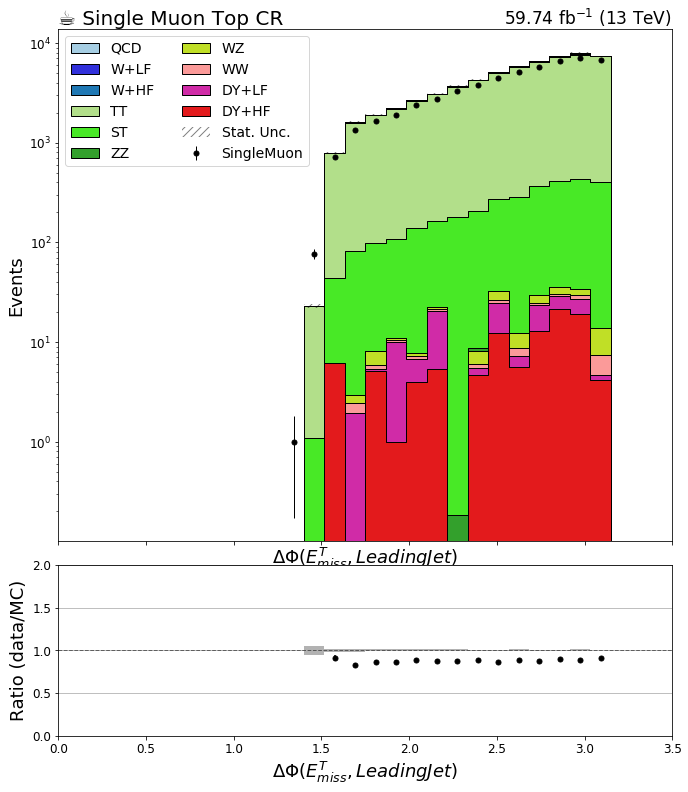

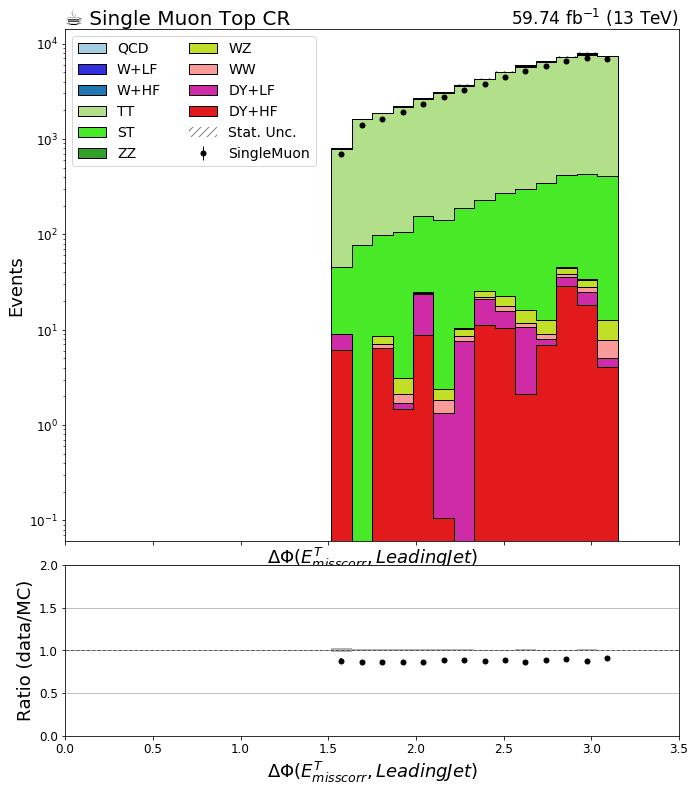

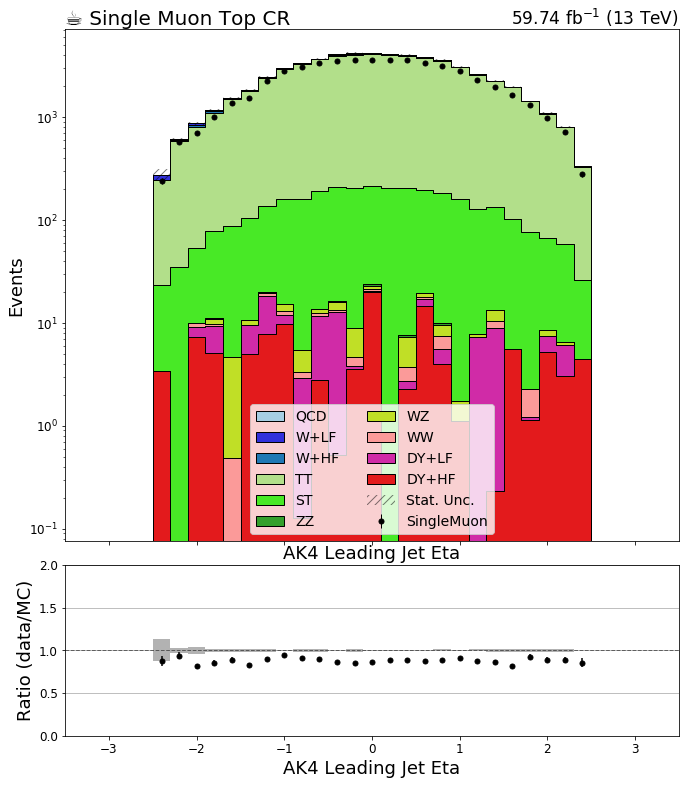

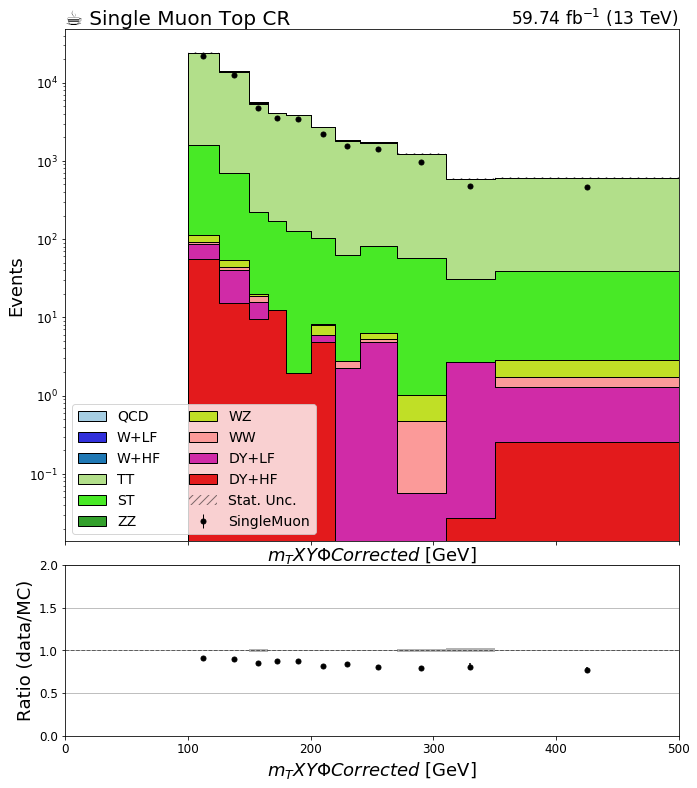

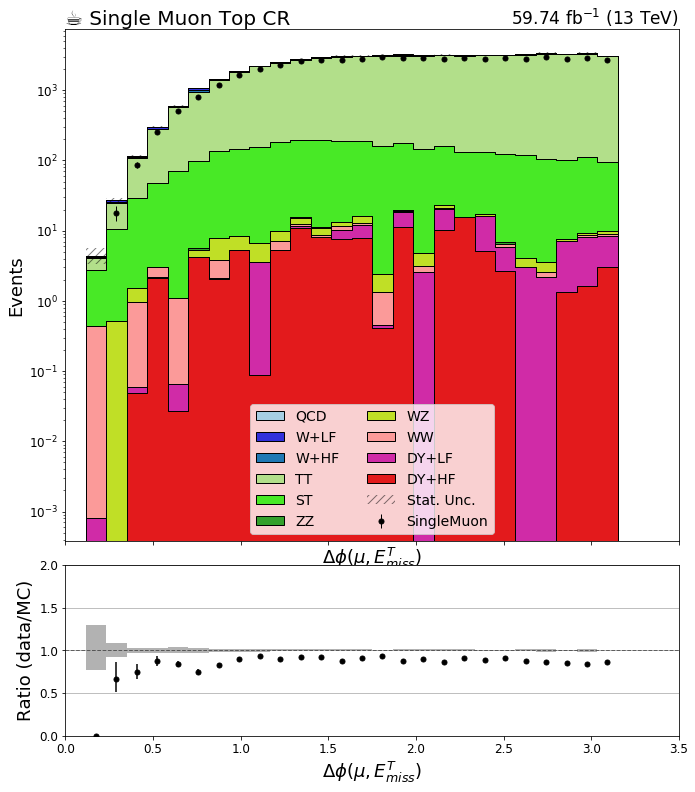

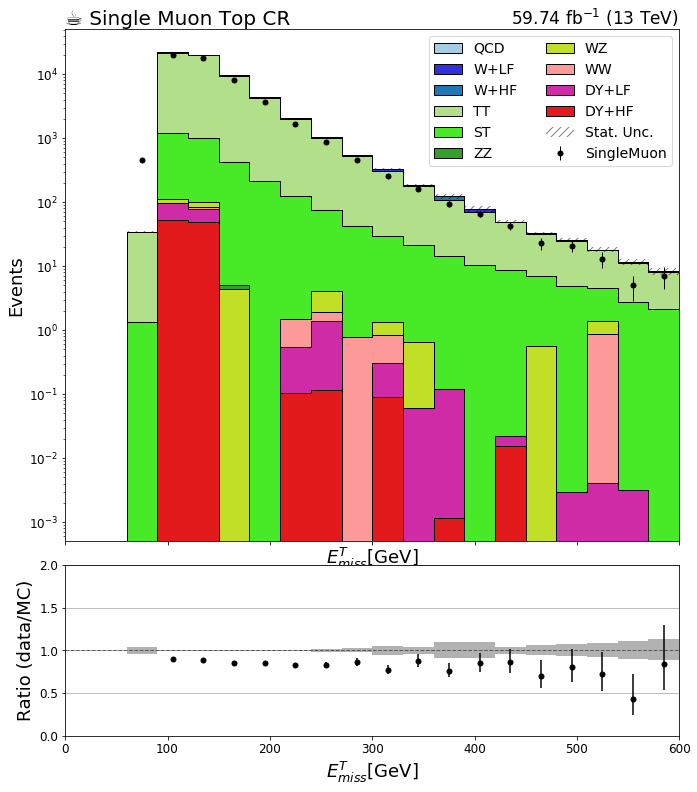

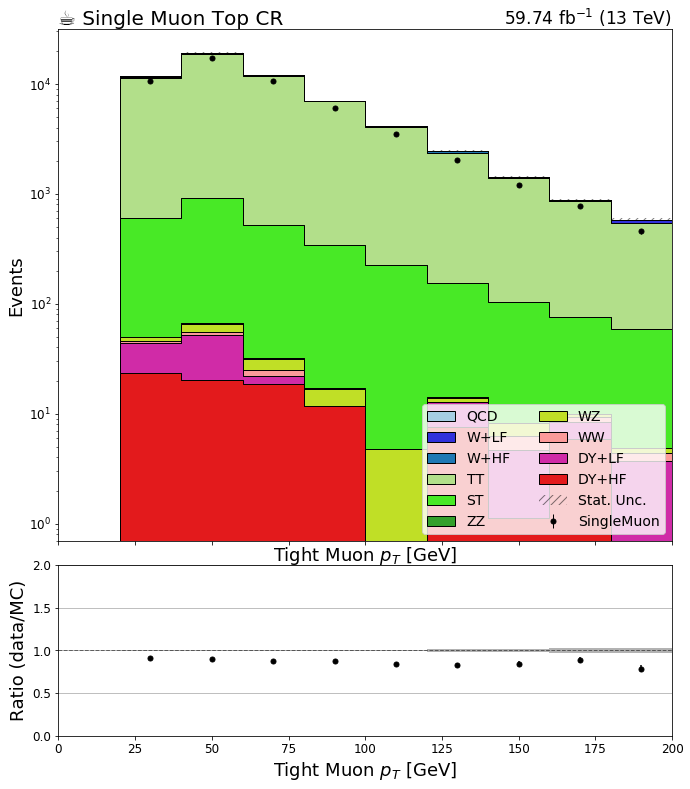

In [6]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

ttbarm
ttbarm
ttbarm
ttbarm


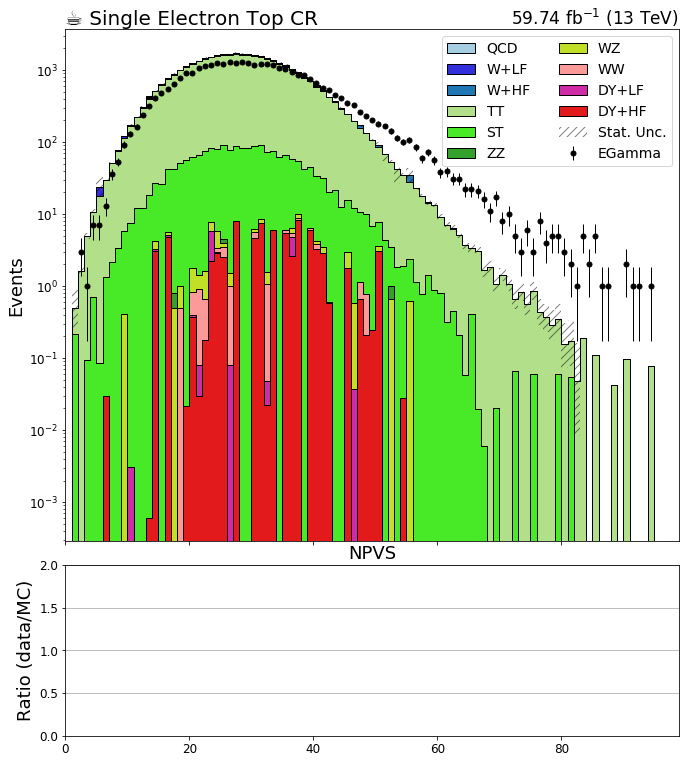

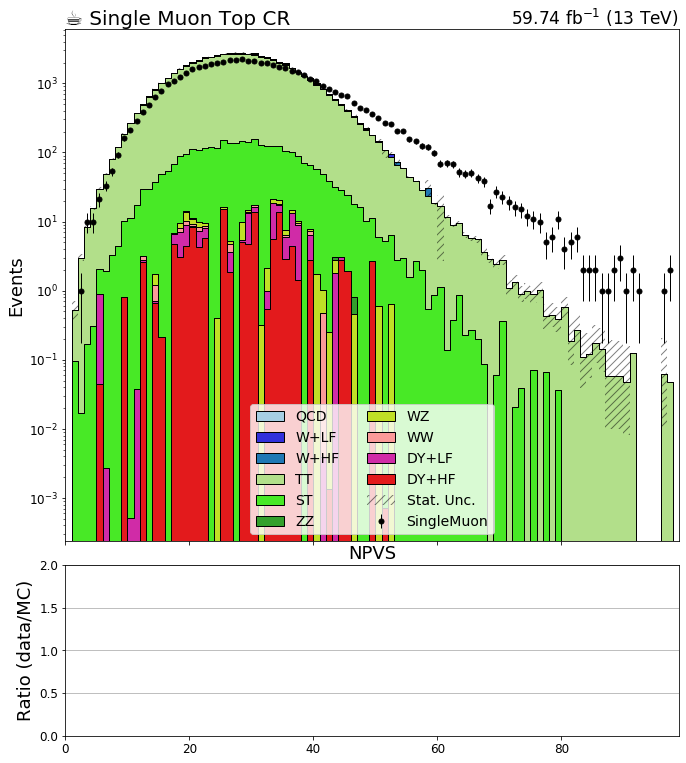

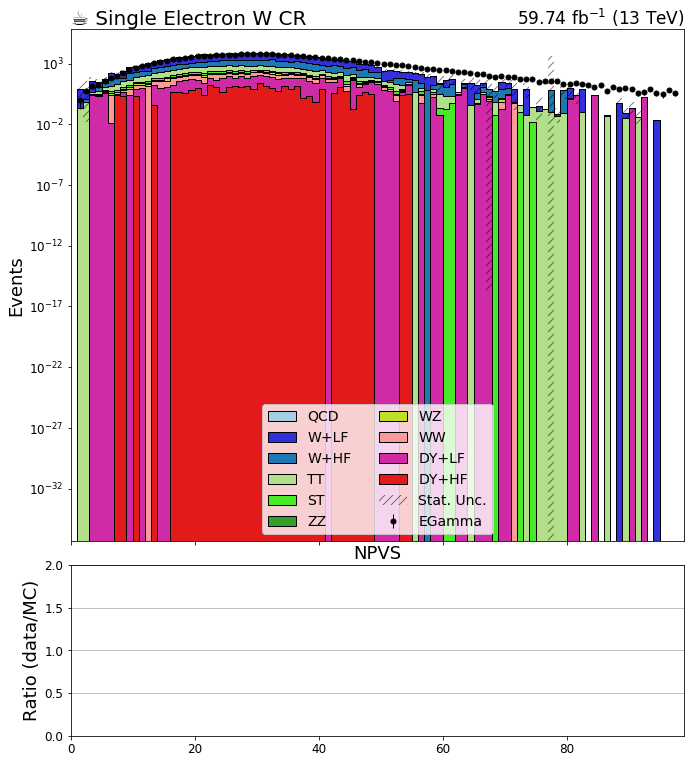

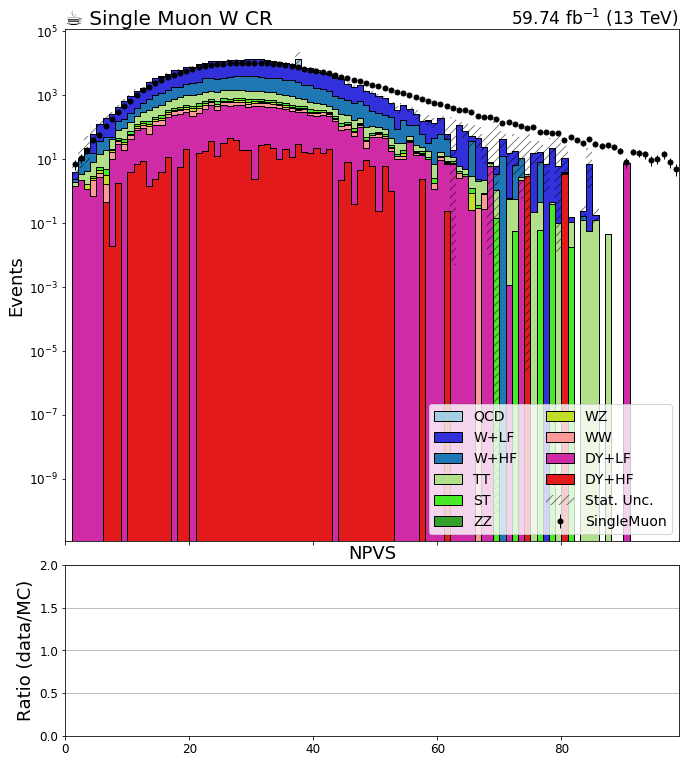

In [7]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
# region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'


for j in bkg_hists[key].identifiers('region'):
    if not (str(j) not  in ['sre', 'srm']): continue
#     legend_opts = {'W+HF':"hi"}

    plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
              '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
              '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


    fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
    fig.subplots_adjust(hspace=.07)
    ax.set_prop_cycle(cycler(color=colors))

    print(region)
    plot.plot1d(data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected')[data[year][str(j)]],            
            overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected'),
            overlay="process",
            ax=ax,
            clear=False,
            stack=True,
            fill_opts=fill_opts,
#             legend_opts=legend_opts,
            error_opts=error_opts
               )

#     plot.plotratio(data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('mT_corrected').integrate('process',data[year][str(j)]), 
#                bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
#                ax=rax,
#                #overflow='over',
#                error_opts=data_err_opts,
#                denom_fill_opts={},
#                guide_opts={},
#                unc='num'
#                )

    rax.set_ylabel('Ratio (data/MC)')
    rax.set_ylim(0.0,2.0)
    rax.grid(axis='y')

    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=2, loc='best')

    coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
#     os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
#     plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
#     plot_name = 'stack_'+key+'.png'
#     fig.savefig(os.path.join(plot_path, plot_name))

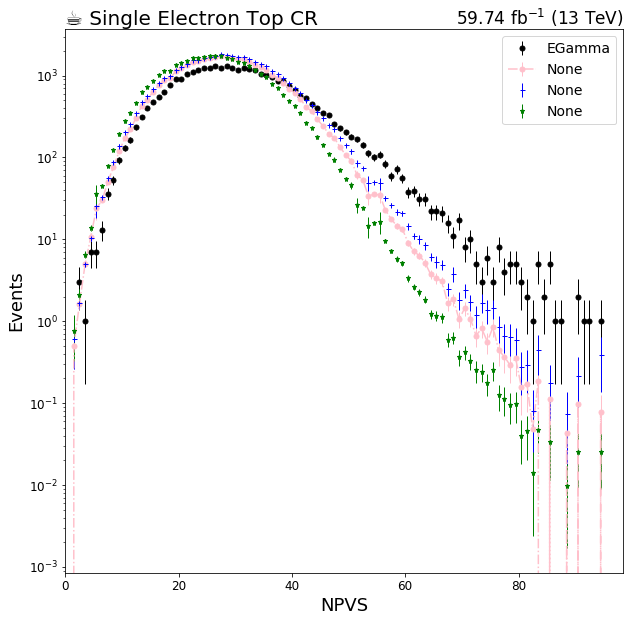

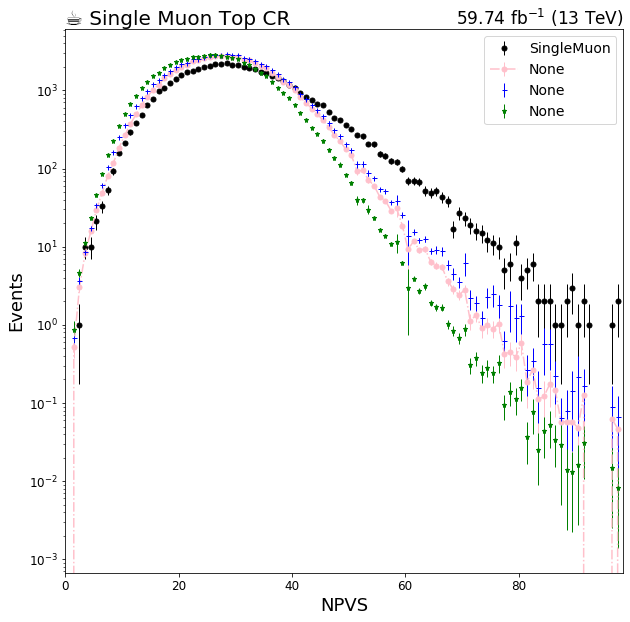

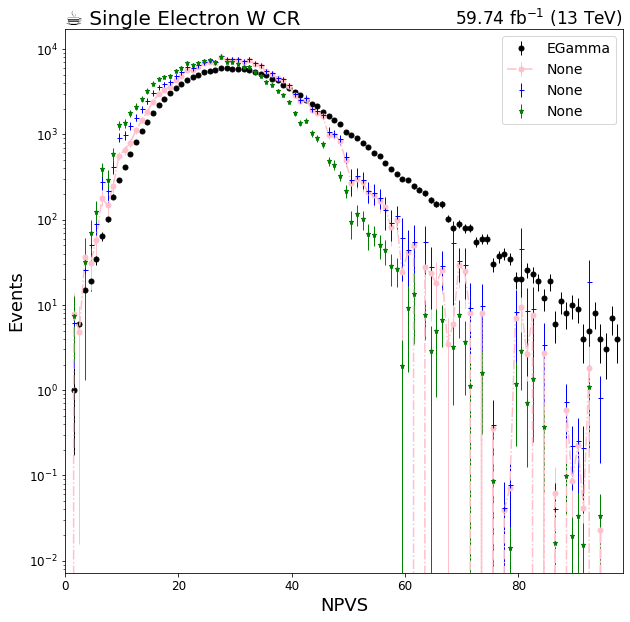

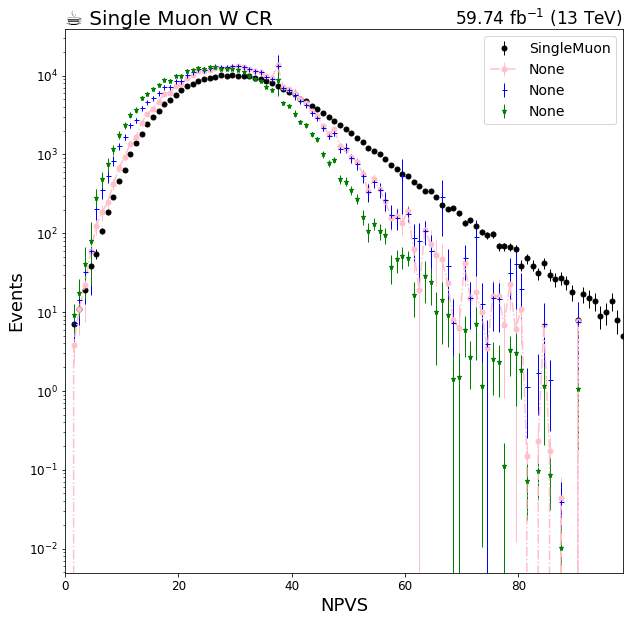

In [8]:


from coffea.hist import plot
import matplotlib.pyplot as plt

R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
for _region in bkg_hists['template'].identifiers('region'):
    if not (str(_region) not  in ['sre', 'srm']): continue
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 0.2,}
#     legend_opts = {'Process':"hi"}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    # nostack_fill_opts = {'alpha': 0.2, 'label': 'hi'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k',  }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_up = {'linestyle':'None', 'marker': '+', 'markersize': 5., 'color':'blue', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_down = {'linestyle':'None', 'marker': '*', 'markersize': 5., 'color':'g', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts = {'linestyle':'-.', 'marker': 'o', 'markersize': 5., 'color':'pink', }#, 'elinewidth': 1, 'emarker': '_'}

    fig, ax = plt.subplots(1,1, figsize=(10,10))
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                      '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                      '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']

    plot.plot1d(data_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected')[data['2018'][str(_region)]],            
    #         overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts,
#                 legend_opts=legend_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected').sum('process'),
#                 overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts,
#                 legend_opts=legend_opts
                   )
    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'pileupUp').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_up
                   )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'pileupDown').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_down,
                   )
    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    # if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=1, loc='best')
    coffee = plt.text(0., 1., u"☕ "+R[str(_region).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)

In [102]:
hbkg = bkg_hists['template'].integrate('region','ttbare').integrate('systematic', 'pileupDown')#.sum('mT_corrected')

In [96]:
hdata=data_hists['template'].integrate('region','ttbare').integrate('systematic', 'nominal')[data['2018']['ttbare']]

In [105]:
hdata.sum('mT_corrected')

<Hist (process,npvs) instance at 0x7f396a6c6668>

In [106]:
hbkg.sum('mT_corrected')

<Hist (process,npvs) instance at 0x7f39663f8c88>

In [100]:
hdata.integrate('mT_corrected').values()

{('EGamma',): array([0.000e+00, 0.000e+00, 3.000e+00, 2.000e+00, 8.000e+00, 9.000e+00,
        1.500e+01, 3.600e+01, 5.100e+01, 1.010e+02, 1.310e+02, 1.670e+02,
        2.430e+02, 3.180e+02, 4.130e+02, 4.830e+02, 5.490e+02, 6.540e+02,
        7.450e+02, 9.190e+02, 9.190e+02, 1.038e+03, 1.106e+03, 1.151e+03,
        1.186e+03, 1.190e+03, 1.269e+03, 1.197e+03, 1.250e+03, 1.212e+03,
        1.117e+03, 1.195e+03, 1.172e+03, 1.130e+03, 9.960e+02, 9.720e+02,
        8.920e+02, 7.800e+02, 8.130e+02, 6.760e+02, 6.110e+02, 5.240e+02,
        4.900e+02, 4.120e+02, 3.680e+02, 3.280e+02, 2.920e+02, 2.430e+02,
        2.070e+02, 1.770e+02, 1.650e+02, 1.540e+02, 1.300e+02, 1.030e+02,
        8.700e+01, 9.900e+01, 8.000e+01, 5.300e+01, 6.500e+01, 5.300e+01,
        3.500e+01, 3.700e+01, 2.800e+01, 2.800e+01, 2.100e+01, 1.900e+01,
        1.800e+01, 1.600e+01, 1.000e+01, 1.500e+01, 8.000e+00, 1.000e+01,
        4.000e+00, 3.000e+00, 7.000e+00, 3.000e+00, 6.000e+00, 2.000e+00,
        4.000e+00, 3.000e

In [57]:
overlay = hdata.sparse_axes()[0].name

In [66]:
overlay = hdata.axis(overlay)

In [68]:
overlay.label

'Process'

In [76]:
hdata.sparse_axes()[0]

<Cat (name=process) instance at 0x7f396ee07080>

In [95]:
hbkg.sparse_axes()[0]

<Cat (name=process) instance at 0x7f396ee07080>

In [88]:
hdata

<Hist (process,mT_corrected) instance at 0x7f395a626860>

In [ ]:
from __future__ import print_function, division
from optparse import OptionParser
from collections import defaultdict, OrderedDict
import concurrent.futures
import sys
import os
import rhalphalib as rl
import numpy as np
import pickle
import gzip
import json
from coffea import hist, processor
from coffea.util import load, save
from scipy import stats
import ROOT

rl.util.install_roofit_helpers()
rl.ParametericSample.PreferRooParametricHist = False

mT_corrected_binning_dict = {
    "2018": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
    "2017": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
    "2016": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])
}



def remap_histograms(hists):
    data_hists = {}
    bkg_hists = {}
    signal_hists = {}

    process = hist.Cat("process", "Process", sorting="placement")
    cats = ("process",)
    sig_map = OrderedDict()
    bkg_map = OrderedDict()
    data_map = OrderedDict()
    bkg_map["Hbb"] = ("Hbb*",)
    bkg_map["DY+jets"] = ("DY+*",)
    bkg_map["VV"] = (["WW", "WZ", "ZZ"],)
    bkg_map["ST"] = ("ST*",)
    bkg_map["TT"] = ("TT*",)
    bkg_map["W+jets"] = ("W+*",)
#     bkg_map["W+HF"] = ("W+HF",)
#     bkg_map["W+LF"] = ("W+LF",)
    bkg_map["Z_jets"] = ("Z+*",)
#     bkg_map["Z+HF"] = ("Z+HF",)
#     bkg_map["Z+LF"] = ("Z+LF",)
#     bkg_map["G+jets"] = ("G+*",)
    bkg_map["QCD"] = ("QCD*",)
    data_map["SingleElectron"] = ("SingleElectron",)
    data_map["SingleMuon"] = ("SingleMuon",)
    data_map["EGamma"] = ("EGamma",)
    sig_map["Mphi1995_Mchi1000"] = ("Mphi-1995_Mchi-1000")
    sig_map["Mphi2000_Mchi1500"] = ("Mphi-2000_Mchi-1500")
    sig_map["Mphi2000_Mchi500"] = ("Mphi-2000_Mchi-500")
#     haven't processed signal yet
    for signal in hists['sig']['template'].identifiers('process'):
        if 'Mchi' not in str(signal): continue
        sig_map[str(signal)] = (str(signal),)  ## signals

    for key in hists["data"].keys():
        bkg_hists[key] = hists["bkg"][key].group(cats, process, bkg_map)
        signal_hists[key] = hists["sig"][key].group(cats, process, sig_map)
        data_hists[key] = hists["data"][key].group(cats, process, data_map)

    print('initial mT_corrected binning',bkg_hists["template"].axis("mT_corrected").edges())


    bkg_hists["template"] = bkg_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    signal_hists["template"] = signal_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    data_hists["template"] = data_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )

    hists = {"bkg": bkg_hists, "data": data_hists, "sig":signal_hists}

    return hists


def addBtagSyst(dictionary, process, region, templ):
    btagUp = template(dictionary, process, "btagUp", region)[0]
    btagDown = template(dictionary, process, "btagDown", region)[0]
    templ.setParamEffect(btag, btagUp, btagDown)

def addVJetsSyst(dictionary, process, region, templ):
    def addSyst(dictionary, process, region, templ, syst, string):
        histogram = dictionary[region].integrate("process", process)
#         print(histogram.integrate("systematic", "nominal").sum('npvs').values()[()])
        nominal=histogram.integrate("systematic", "nominal").sum('npvs').values()[()]
        up=histogram.integrate("systematic", string+"Up").sum('npvs').values()[()]
        down=histogram.integrate("systematic",string+"Down").sum('npvs').values()[()]
        systUp = np.array( up.sum() / nominal.sum() )
        systUp[np.isnan(systUp)] = 1.
        systUp = systUp.sum()
        templ.setParamEffect(syst, systUp)
#     addSyst(dictionary, process, region, templ, ew1, "ew1")
#     addSyst(dictionary, process, region, templ, ew2W, "ew2W")
#     addSyst(dictionary, process, region, templ, ew2Z, "ew2Z")
#     addSyst(dictionary, process, region, templ, ew3W, "ew3W")
#     addSyst(dictionary, process, region, templ, ew3Z, "ew3Z")
#     addSyst(dictionary, process, region, templ, mix, "mix")
#     addSyst(dictionary, process, region, templ, qcd1, "qcd1")
#     addSyst(dictionary, process, region, templ, qcd2, "qcd2")
#     addSyst(dictionary, process, region, templ, qcd3, "qcd3")
    addSyst(dictionary, process, region, templ, muR, "muR")
    addSyst(dictionary, process, region, templ, muF, "muF")
    
def template(dictionary, process, systematic, region, read_sumw2=False):
    histogram = dictionary[region].integrate("process", process).sum('npvs')
    nominal, sumw2 = histogram.integrate("systematic", "nominal").values(sumw2=True)[()]
    zerobins = nominal <= 0.
    output = nominal
    
    if "nominal" not in systematic and "data" not in systematic:
    #print('Normalizing',systematic,'histogram of',process,'in region',region)
        output = histogram.integrate("systematic", systematic).values()[()]
        output[zerobins] = 1.
        output[~zerobins] /= nominal[~zerobins]
        output[np.isnan(output)] = 1.
    binning = (
        dictionary[region]
        .integrate("process", process)
        .integrate("systematic", systematic)
        .axis("mT_corrected")
        .edges()
    )
    if read_sumw2:
        return (output, binning, "mT_corrected", sumw2)
    return (output, binning, "mT_corrected")

def model(year):

#     model_id = year + category + "recoil" + str(recoil)
#     print(model_id)
#     model = rl.Model(str(s) + model_id)



    model_id = 'w'
    model = rl.Model(model_id)
    ch_name = "ttbare" 
    # Create a channel/Control region
    ttbare = rl.Channel(ch_name)
    # add the Channel/CR to the model
    model.addChannel(ttbare)
    
    ###
    # Add data distribution to the channel
    ###

    if year == "2018":
        ttbare.setObservation(template(data, "EGamma", "data", "ttbare"))
    else:
        ttbare.setObservation(template(data, "SingleElectron", "data","ttbare"))
        
    #template for signal
    for s in signal['ttbare'].identifiers('process'):
        print(s)
        if 'Mphi1995' not in str(s): continue
        ttbare_signalTemplate = template(signal,s,'nominal','ttbare')
        ttbare_signal=rl.TemplateSample(ch_name+'_'+str(s), rl.Sample.SIGNAL, ttbare_signalTemplate)
        ttbare_signal.setParamEffect(lumi, 1.015)
    #     sr_signal.setParamEffect(trig_met, 1.01)
    #     sr_signal.setParamEffect(veto_tau, 1.03)
    #     sr_signal.setParamEffect(jec, 1.05)
        #btag
        btagUp=template(signal, s,'btagUp','ttbare')[0]
        btagDown=template(signal, s,'btagDown','ttbare')[0]
        ttbare_signal.setParamEffect(btag, btagUp, btagDown)
#         #trigger Electron
        trigeUp=template(signal, s, 'trig_eUp', 'ttbare')[0] 
        trigeDown=template(signal, s, 'trig_eDown', 'ttbare')[0]
        ttbare_signal.setParamEffect(trig_e, trigeUp, trigeDown)
#         #id Electron
        id_eUp=template(signal, s, 'id_eUp', 'ttbare')[0] 
        id_eDown=template(signal, s, 'id_eDown', 'ttbare')[0]
        ttbare_signal.setParamEffect(id_e, id_eUp, id_eDown)
        #pileup
        pileupUp=template(signal, s,'pileupUp','ttbare')[0] 
        pileupDown=template(signal, s,'pileupDown','ttbare')[0] 
        ttbare_signal.setParamEffect(pileup, pileupUp, pileupDown)
        
        #reco Electron
        recoeUp=template(signal, s, 'reco_eUp', 'ttbare')[0] 
        recoDown=template(signal, s, 'reco_eDown', 'ttbare')[0]
        ttbare_signal.setParamEffect(reco_e, recoeUp, recoDown)
#         ttbare_signal.autoMCStats()
        ttbare.addSample(ttbare_signal)
    ###
    # W(->lnu)+jets data-driven model
    ###

    ttbare_wjetsTemplate = template(background, "W+jets", "nominal", "ttbare", read_sumw2=True)
    ttbare_wjetsMC = rl.TemplateSample(
        ch_name + "_wjetsMC",
        rl.Sample.BACKGROUND,
        ttbare_wjetsTemplate
    )
    ttbare_wjetsMC.setParamEffect(lumi, 1.015)
#     ttbare_wjetsMC.setParamEffect(trig_e, 1.01)
#     ttbare_wjetsMC.setParamEffect(veto_tau, 1.03)
#     ttbare_wjetsMC.setParamEffect(wjets_norm, 1.4)
#     ttbare_wjetsMC.setParamEffect(jec, 1.05)
#     ttbare_wjetsMC.setParamEffect(id_e, 1.02)
#     ttbare_wjetsMC.setParamEffect(reco_e, 1.02)
#     ttbare_wjetsMC.autoMCStats()
#     addBtagSyst(background, "W+jets", "ttbare", ttbare_wjetsMC)
    #trigger Electron
    trigeUp=template(background, 'W+jets', 'trig_eUp', 'ttbare')[0] 
    trigeDown=template(background, 'W+jets', 'trig_eDown', 'ttbare')[0]
    ttbare_wjetsMC.setParamEffect(trig_e, trigeUp, trigeDown)
#     #id Electron
    id_eUp=template(background, "W+jets", 'id_eUp', 'ttbare')[0] 
    id_eDown=template(background, "W+jets", 'id_eDown', 'ttbare')[0]
    ttbare_wjetsMC.setParamEffect(id_e, id_eUp, id_eDown)
    #pileup
    pileupUp=template(background, 'W+jets','pileupUp','ttbare')[0] 
    pileupDown=template(background, 'W+jets','pileupDown','ttbare')[0] 
    ttbare_wjetsMC.setParamEffect(pileup, pileupUp, pileupDown)
    #reco Electron
    recoeUp=template(background, 'W+jets', 'reco_eUp', 'ttbare')[0] 
    recoDown=template(background, 'W+jets', 'reco_eDown', 'ttbare')[0]
    ttbare_wjetsMC.setParamEffect(trig_e, recoeUp, recoDown)
#     addVJetsSyst(background, "W+jets", "ttbare", ttbare_wjetsMC)
    ttbare.addSample(ttbare_wjetsMC)

    # ###
    # # top-antitop model
    # ###

    ttbare_ttTemplate = template(background, "TT", "nominal","ttbare", read_sumw2=True)
    ttbare_ttMC = rl.TemplateSample(
        ch_name + "_ttMC",
        rl.Sample.BACKGROUND,
        ttbare_ttTemplate
    )
    ttbare_ttMC.setParamEffect(lumi, 1.015)
#     ttbare_ttMC.setParamEffect(trig_e, 1.01)
#     ttbare_ttMC.setParamEffect(veto_tau, 1.03)
#     ttbare_ttMC.setParamEffect(jec, 1.05)
#     ttbare_ttMC.setParamEffect(id_e, 1.02)
#     ttbare_ttMC.setParamEffect(reco_e, 1.02)
    addBtagSyst(background, "TT", "ttbare", ttbare_ttMC)
#     ttbare_ttMC.autoMCStats()
    #trigger Electron
    trigeUp=template(background, 'TT', 'trig_eUp', 'ttbare')[0] 
    trigeDown=template(background, 'TT', 'trig_eDown', 'ttbare')[0]
    ttbare_ttMC.setParamEffect(trig_e, trigeUp, trigeDown)
    #id Electron
    id_eUp=template(background, "TT", 'id_eUp', 'ttbare')[0] 
    id_eDown=template(background, "TT", 'id_eDown', 'ttbare')[0]
    ttbare_ttMC.setParamEffect(id_e, id_eUp, id_eDown)
    #pileup
    pileupUp=template(background, 'TT','pileupUp','ttbare')[0] 
    pileupDown=template(background, 'TT','pileupDown','ttbare')[0] 
    ttbare_ttMC.setParamEffect(pileup, pileupUp, pileupDown)
    #reco Electron
    recoeUp=template(background, 'TT', 'reco_eUp', 'ttbare')[0] 
    recoDown=template(background, 'TT', 'reco_eDown', 'ttbare')[0]
    ttbare_ttMC.setParamEffect(reco_e, recoeUp, recoDown)
    # ttbare_ttMC.setParamEffect(ttMC_norm, 1.2)
    ttbare.addSample(ttbare_ttMC)

    # ###
    # # Other MC-driven processes
    # ###
    # ST Background
    ttbare_stTemplate = template(background, "ST", "nominal", "ttbare")
    ttbare_st = rl.TemplateSample(
        ch_name + "_stMC", rl.Sample.BACKGROUND, ttbare_stTemplate
    )
    ttbare_st.setParamEffect(lumi, 1.015)
#     ttbare_st.setParamEffect(trig_e, 1.01)
#     ttbare_st.setParamEffect(veto_tau, 1.03)
#     ttbare_st.setParamEffect(st_norm, 1.2) something related to signal
#     ttbare_st.setParamEffect(jec, 1.05)
#     ttbare_st.setParamEffect(id_e, 1.02)
#     ttbare_st.setParamEffect(reco_e, 1.02)
    addBtagSyst(background, "ST", "ttbare", ttbare_st)
#     ttbare_st.autoMCStats()
    #trigger Electron
    trigeUp=template(background, 'ST', 'trig_eUp', 'ttbare')[0] 
    trigeDown=template(background, 'ST', 'trig_eDown', 'ttbare')[0]
    ttbare_st.setParamEffect(trig_e, trigeUp, trigeDown)
    #id Electron
    id_eUp=template(background, "ST", 'id_eUp', 'ttbare')[0] 
    id_eDown=template(background, "ST", 'id_eDown', 'ttbare')[0]
    ttbare_st.setParamEffect(id_e, id_eUp, id_eDown)
    #pileup
    pileupUp=template(background, 'ST','pileupUp','ttbare')[0] 
    pileupDown=template(background, 'ST','pileupDown','ttbare')[0] 
    ttbare_st.setParamEffect(pileup, pileupUp, pileupDown)
    #reco Electron
    recoeUp=template(background, 'ST', 'reco_eUp', 'ttbare')[0] 
    recoDown=template(background, 'ST', 'reco_eDown', 'ttbare')[0]
    ttbare_st.setParamEffect(reco_e, recoeUp, recoDown)
    ttbare.addSample(ttbare_st)

    # DY Jet Background
    ttbare_dyjetsTemplate = template(background, "DY+jets", "nominal","ttbare")
    ttbare_dyjets = rl.TemplateSample(
        ch_name + "_dyjetsMC", rl.Sample.BACKGROUND, ttbare_dyjetsTemplate
    )
    ttbare_dyjets.setParamEffect(lumi, 1.015)
#     ttbare_dyjets.setParamEffect(trig_e, 1.01)
#     ttbare_dyjets.setParamEffect(veto_tau, 1.03)
#     ttbare_dyjets.setParamEffect(zjetsMC_norm, 1.4)
#     ttbare_dyjets.setParamEffect(jec, 1.05)
#     ttbare_dyjets.setParamEffect(id_e, 1.02)
#     ttbare_dyjets.setParamEffect(reco_e, 1.02)
    addBtagSyst(background, "DY+jets", "ttbare", ttbare_dyjets)
    addVJetsSyst(background,"DY+jets", "ttbare", ttbare_dyjets)
#     ttbare_dyjets.autoMCStats()
    #trigger Electron
    trigeUp=template(background, 'DY+jets', 'trig_eUp', 'ttbare')[0] 
    trigeDown=template(background, 'DY+jets', 'trig_eDown', 'ttbare')[0]
    ttbare_dyjets.setParamEffect(trig_e, trigeUp, trigeDown)
    #id Electron
    id_eUp=template(background, "DY+jets", 'id_eUp', 'ttbare')[0] 
    id_eDown=template(background, "DY+jets", 'id_eDown', 'ttbare')[0]
    ttbare_dyjets.setParamEffect(id_e, id_eUp, id_eDown)
    #pileup
    pileupUp=template(background, 'DY+jets','pileupUp','ttbare')[0] 
    pileupDown=template(background, 'DY+jets','pileupDown','ttbare')[0] 
    ttbare_dyjets.setParamEffect(pileup, pileupUp, pileupDown)
    #reco Electron
    recoeUp=template(background, 'DY+jets', 'reco_eUp', 'ttbare')[0] 
    recoDown=template(background, 'DY+jets', 'reco_eDown', 'ttbare')[0]
    ttbare_dyjets.setParamEffect(reco_e, recoeUp, recoDown)
    ttbare.addSample(ttbare_dyjets)


    # V Jets Background
    ttbare_vvTemplate = template(background, "VV", "nominal", "ttbare")
    ttbare_vv = rl.TemplateSample(
        ch_name + "_vvMC", rl.Sample.BACKGROUND, ttbare_vvTemplate
    )
    ttbare_vv.setParamEffect(lumi, 1.015)
#     ttbare_vv.setParamEffect(trig_e, 1.01)
#     ttbare_vv.setParamEffect(veto_tau, 1.03)
#     ttbare_vv.setParamEffect(vv_norm, 1.2)
#     ttbare_vv.setParamEffect(jec, 1.05)
#     ttbare_vv.setParamEffect(id_e, 1.02)
#     ttbare_vv.setParamEffect(reco_e, 1.02)
    addBtagSyst(background, "VV", "ttbare", ttbare_vv)
#     ttbare_vv.autoMCStats()
#     #trigger Electron
    trigeUp=template(background, 'VV', 'trig_eUp', 'ttbare')[0] 
    trigeDown=template(background, 'VV', 'trig_eDown', 'ttbare')[0]
    ttbare_vv.setParamEffect(trig_e, trigeUp, trigeDown)
#     #id Electron
    id_eUp=template(background, "VV", 'id_eUp', 'ttbare')[0] 
    id_eDown=template(background, "VV", 'id_eDown', 'ttbare')[0]
    ttbare_vv.setParamEffect(id_e, id_eUp, id_eDown)
    #pileup
    pileupUp=template(background, 'VV','pileupUp','ttbare')[0] 
    pileupDown=template(background, 'VV','pileupDown','ttbare')[0] 
    ttbare_vv.setParamEffect(pileup, pileupUp, pileupDown)
    #reco Electron
    recoeUp=template(background, 'VV', 'reco_eUp', 'ttbare')[0] 
    recoDown=template(background, 'VV', 'reco_eDown', 'ttbare')[0]
    ttbare_vv.setParamEffect(reco_e, recoeUp, recoDown)
    
    ttbare.addSample(ttbare_vv)

    # QCD background
    ttbare_qcdTemplate = template(background, "QCD", "nominal", "ttbare")
    ttbare_qcd = rl.TemplateSample(
        ch_name + "_qcdMC", rl.Sample.BACKGROUND, ttbare_qcdTemplate
    )
    ttbare_qcd.setParamEffect(lumi, 1.015)
#     ttbare_qcd.setParamEffect(trig_e, 1.01)
#     ttbare_qcd.setParamEffect(veto_tau, 1.03)
#     ttbare_qcd.setParamEffect(qcde_norm, 2.0)
#     ttbare_qcd.setParamEffect(jec, 1.05)
#     ttbare_qcd.setParamEffect(id_e, 1.02)
#     ttbare_qcd.setParamEffect(reco_e, 1.02)
    addBtagSyst(background, "QCD", "ttbare", ttbare_qcd)
#     ttbare_qcd.autoMCStats()
    #trigger Electron
    trigeUp=template(background, 'QCD', 'trig_eUp', 'ttbare')[0] 
    trigeDown=template(background, 'QCD', 'trig_eDown', 'ttbare')[0]
    ttbare_qcd.setParamEffect(trig_e, trigeUp, trigeDown)
#     #id Electron
    id_eUp=template(background, "QCD", 'id_eUp', 'ttbare')[0] 
    id_eDown=template(background, "QCD", 'id_eDown', 'ttbare')[0]
    ttbare_qcd.setParamEffect(id_e, id_eUp, id_eDown)
    #pileup
#     pileupUp=template(background, 'QCD','pileupUp','ttbare')[0] 
#     pileupDown=template(background, 'QCD','pileupDown','ttbare')[0] 
#     ttbare_qcd.setParamEffect(pileup, pileupUp, pileupDown)
    #reco Electron
    recoeUp=template(background, 'QCD', 'reco_eUp', 'ttbare')[0] 
    recoDown=template(background, 'QCD', 'reco_eDown', 'ttbare')[0]
    ttbare_qcd.setParamEffect(reco_e, recoeUp, recoDown)
    
    ttbare.addSample(ttbare_qcd)
    return model

if __name__ == "__main__":
    if not os.path.exists("datacards"):
        os.mkdir("datacards")
    parser = OptionParser()
    parser.add_option("-y", "--year", help="year", dest="year", default="")
    (options, args) = parser.parse_args()
    year = options.year
    year = '2018'

    mT_corrected_binning_dict = {
        "2018": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
        "2017": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
        "2016": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])
    }
    mT_corrected_binning = mT_corrected_binning_dict[year]
    mT_correctedbins = np.array(mT_corrected_binning)
    nmT_corrected = len(mT_correctedbins) - 1

    ###
    # Extract histograms from input file
    ###

    print("Grouping histograms")
    hists = load("hists/UL_lep_monotop_v1_test_" + year + ".scaled")
    hists = remap_histograms(hists)
    data_hists = hists["data"]
    bkg_hists = hists["bkg"]
    signal_hists = hists["sig"]

    ###
    # Preparing histograms for fit
    ##

    data = {}
    for r in data_hists["template"].identifiers("region"):
        data[str(r)] = data_hists["template"].integrate("region", r)

    background = {}
    for r in bkg_hists["template"].identifiers("region"):
        background[str(r)] = bkg_hists["template"].integrate("region", r)

    signal = {}
    for r in signal_hists["template"].identifiers("region"):
        signal[str(r)] = signal_hists["template"].integrate("region", r)
    ###
    ###
    # Setting up systematics
    ###
    ###
    lumi = rl.NuisanceParameter("lumi" + year, "lnN")
    zjets_norm = rl.NuisanceParameter("zjets_norm", "lnN")
    wjets_norm = rl.NuisanceParameter("wjets_norm", "lnN")
    tt_norm = rl.NuisanceParameter("tt_norm", "lnN")
    id_e = rl.NuisanceParameter("id_e" + year, "shape")
    id_mu = rl.NuisanceParameter("id_mu" + year, "lnN")
    id_pho = rl.NuisanceParameter("id_pho" + year, "lnN")
    reco_e = rl.NuisanceParameter("reco_e" + year, "shape")
    iso_mu = rl.NuisanceParameter("iso_mu" + year, "lnN")
    trig_e = rl.NuisanceParameter("trig_e" + year, "shape")
    trig_met = rl.NuisanceParameter("trig_met" + year, "lnN")
    trig_pho = rl.NuisanceParameter("trig_pho" + year, "lnN")
    veto_tau = rl.NuisanceParameter("veto_tau" + year, "lnN")
    jec = rl.NuisanceParameter("jec" + year, "lnN")
    #btag = rl.NuisanceParameter("btag" + year, "shapeN")  # AK4 btag
    btag = rl.NuisanceParameter("btag" + year, "shape")  # AK4 btag
    ew1 = rl.NuisanceParameter("ew1", "lnN")
    #ew2G = rl.NuisanceParameter("ew2G", "lnN")
    ew2W = rl.NuisanceParameter("ew2W", "lnN")
    ew2Z = rl.NuisanceParameter("ew2Z", "lnN")
    #ew3G = rl.NuisanceParameter("ew3G", "lnN")
    ew3W = rl.NuisanceParameter("ew3W", "lnN")
    ew3Z = rl.NuisanceParameter("ew3Z", "lnN")
    mix = rl.NuisanceParameter("mix", "lnN")
    muF = rl.NuisanceParameter("muF", "lnN")
    muR = rl.NuisanceParameter("muR", "lnN")
    qcd1 = rl.NuisanceParameter("qcd1", "lnN")
    qcd2 = rl.NuisanceParameter("qcd2", "lnN")
    qcd3 = rl.NuisanceParameter("qcd3", "lnN")
    whf_fraction = rl.NuisanceParameter("whf_fraction", "lnN")
    zhf_fraction = rl.NuisanceParameter("zhf_fraction", "lnN")
    #ghf_fraction = rl.NuisanceParameter("ghf_fraction", "shapeN")
    pileup = rl.NuisanceParameter("pileup"+year, "shape")
    
    with open(
        "data/"+"test_ttbare"+year+".model",
        "wb",) as fout:
        pickle.dump(model(year), fout, protocol=2)

In [10]:
import numpy as np

In [12]:
a =np.array([1,2,3])

In [14]:
[i+(0.1*i) for i in a if i >2]

[3.3]